<a href="https://colab.research.google.com/github/crsah234/anyangUniverSity_Third_second/blob/main/HMDA_MA_2025_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HMDA Massachusetts 주택구입 대출 EDA — 2025

**목표:** 데이터 구조·분포·승인/거절과의 관계·결측 및 품질 문제를 이해한다. 모델은 만들지 않는다.

- 분석 대상: 제공받은 `actions_taken_1-2-3_loan_purposes_1_state_MA.csv`의 전체 행.
- `df_raw`는 원본 그대로 유지한다. `df`는 요청한 **17개 변수만** 복사하며 끝까지 모든 행을 보존한다.
- 승인/거절 `decision`은 별도 Series이다. `action_taken`을 덮어쓰지 않는다.
- 숫자 변환은 임시 `numeric` 또는 `s`에서만 수행한다. 변환 불가 값은 숫자 요약·그래프에서만 제외하며 해당 개수를 표시한다. 결측 삭제·대치·이상값 제거·변수 삭제는 하지 않는다.
- 표·해석의 숫자는 **제공 CSV를 직접 집계한 결과**이며, 공식 자료는 변수 정의와 공개 방식·코드 해석에 사용한다. 확인일: 2026-11-04.

**읽는 순서:** ① 구조 → ② 타깃 → ③ 결측·특수값 → ④ 단변량 → ⑤ 타깃과의 관계 → ⑥ County → ⑦ 변수 간 관계 → ⑧ 품질 → ⑨ 판단.

> 제공 파일에 대한 EDA이다. 1행은 대출/신청 기록이며 고유한 사람 수가 아니다. Action 1·2·3만 포함하므로 여기의 거절률을 Massachusetts의 모든 신청에 대한 거절률로 확대하지 않는다.

## 0. 변수와 계산 기준

| 변수 | 의미·단위 | 읽을 때 주의할 점 |
|---|---|---|
| `action_taken` | 1 실행, 2 승인 후 미수락, 3 거절 | 1+2를 금융기관 기준 승인으로 집계 |
| `income` | 심사에서 사용한 연간 총소득, **천 USD** | 153은 153,000 USD. 개인 단독소득으로 단정하지 않음 |
| `loan_amount` | 실행 대출금액 또는 신청금액, USD | 1은 실행금액, 2·3은 신청금액이라는 차이가 있음 |
| `debt_to_income_ratio` | 월 총부채/월소득 비율, % | 숫자와 공개 구간이 섞여 있음 |
| `loan_to_value_ratio` | 이 프로젝트에서 CLTV로 해석, % | 해당 부동산 담보 총부채/심사 담보가치 |
| `property_value` | 심사에 사용한 부동산 가치, USD | 매매가격과 동일하다고 단정하지 않음 |
| `loan_term` | 만기까지 기간, **개월** | 360개월 = 30년 |
| `loan_type` | 1 Conventional, 2 FHA, 3 VA, 4 RHS/FSA | 정부 보험·보증에 따른 구분 |
| `lien_status` | 1 선순위, 2 후순위 담보권 | 2가 반드시 정확히 2순위라는 뜻은 아님 |
| `occupancy_type` | 1 주거주, 2 제2주택, 3 투자용 | 상품·신청자 구성 차이 가능 |
| `county_code` | 5자리 State–County FIPS | 수치의 크기에 의미 없음 |
| `applicant_age` | 신청자 연령대 | 8888 = 해당 없음, 실제 나이 아님 |
| `derived_sex` | 신청자·공동신청자 정보를 집계한 성별 | Joint를 개인의 별도 성별로 해석하지 않음 |
| `derived_race` | 신청자·공동신청자 정보를 집계한 인종 | Not Available·Free Form Text Only 구분 |
| `derived_ethnicity` | 집계된 Hispanic/Latino 계열 구분 | race와 별도 구분이며 국적이 아님 |
| `preapproval` | 사전승인 프로그램의 요청 여부 | 1 요청, 2 미요청. 승인 성공 여부를 뜻하는 변수가 아님 |
| `total_units` | 담보 부동산과 관련된 전체 주거단위 수(세대수) | 거주자·가구원 수가 아님. 1~4는 개수, 5 이상은 공개 구간 |

정의 출처: [HMDA 공개 필드](https://ffiec.cfpb.gov/documentation/publications/loan-level-datasets/lar-data-fields), [2025 FIG](https://ffiec.cfpb.gov/documentation/fig/2025/overview). 이 CSV의 열 이름은 `loan_to_value_ratio`이고 공식 공개 필드 문서의 명칭은 `combined_loan_to_value_ratio`이다. 요청한 CLTV 의미로 분석하되 열 이름을 바꾸거나 `loan_amount / property_value`로 재계산하지 않는다.

**공통 계산:** 비율(%) = 해당 건수 ÷ 전체 70,304건 × 100. 범주별 거절률(%) = 해당 범주의 거절 건수 ÷ 해당 범주의 전체 건수 × 100. 수치형 요약의 분모는 해당 값이 숫자로 관측된 건수이다. 반올림은 표시에만 적용한다.

### 실행 준비
CSV와 이 노트북을 같은 폴더에 두고 위에서부터 실행한다. 이미 `df_raw`를 읽어 둔 경우에도 아래 셀로 같은 원본을 다시 읽을 수 있다. `CSV_PATH`만 실제 위치에 맞춘다. 그래프는 환경별 한글 폰트 문제를 피하기 위해 영문 표기를 사용하며 설명은 한국어로 작성했다.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

CSV_PATH = "actions_taken_1-2-3_loan_purposes_1_state_MA.csv"
df_raw = pd.read_csv(CSV_PATH)

selected_columns = [
    "action_taken", "income", "loan_amount", "debt_to_income_ratio",
    "loan_to_value_ratio", "property_value", "loan_term", "loan_type",
    "lien_status", "occupancy_type", "county_code", "applicant_age",
    "derived_sex", "derived_race", "derived_ethnicity",
    "preapproval", "total_units"
]
df = df_raw[selected_columns].copy()

# CSV에 적힌 문자열을 확인하기 위한 자료. df_raw나 df를 바꾸지 않는다.
df_text = pd.read_csv(CSV_PATH, dtype=str, keep_default_na=False,
                      usecols=selected_columns)
df_text = df_text[selected_columns]

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.3f}".format)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.15

# 원본을 복제하는 대신 비교용 해시를 기록한다.
raw_hash_before = pd.util.hash_pandas_object(df_raw, index=True)
raw_columns_before = df_raw.columns.tolist()
print("원본:", df_raw.shape, "분석용:", df.shape)

원본: (70304, 99) 분석용: (70304, 17)


**해석:** 원본은 70,304행·99열이고 분석용 `df`는 70,304행·17열이다. 제외된 열은 이번 EDA의 분석변수로 쓰지 않는다. `df_text`는 CSV에 실제로 적힌 `NA`와 빈칸을 구분하기 위한 점검용 복사본이다. 기본 `read_csv`가 `NA`를 `NaN`으로 해석했더라도 원래 표기를 확인할 수 있다.

## ① 데이터 기본 구조
### 1-1. 파일의 범위와 앞부분
2025년·MA·주택구입·Action 1/2/3 조건이 실제 파일과 일치하는지 먼저 확인한다. 이 셀의 연도·주·목적 열은 원본 범위 확인에만 사용하고 `df`에는 추가하지 않는다.

In [ ]:
print("원본 행·열:", df_raw.shape)
print("분석용 변수명:", df.columns.tolist())
display(df_raw[["activity_year", "state_code", "loan_purpose"]].value_counts())
print("action_taken unique:", sorted(df["action_taken"].unique()))
display(df.head())
assert df_raw["activity_year"].eq(2025).all()
assert df_raw["state_code"].eq("MA").all()
assert df_raw["loan_purpose"].eq(1).all()
assert df["action_taken"].isin([1, 2, 3]).all()

원본 행·열: (70304, 99)
분석용 변수명: ['action_taken', 'income', 'loan_amount', 'debt_to_income_ratio', 'loan_to_value_ratio', 'property_value', 'loan_term', 'loan_type', 'lien_status', 'occupancy_type', 'county_code', 'applicant_age', 'derived_sex', 'derived_race', 'derived_ethnicity', 'preapproval', 'total_units']


activity_year  state_code  loan_purpose
2025           MA          1               70304
Name: count, dtype: int64

action_taken unique: [np.int64(1), np.int64(2), np.int64(3)]


,action_taken,income,loan_amount,debt_to_income_ratio,loan_to_value_ratio,property_value,loan_term,loan_type,lien_status,occupancy_type,county_code,applicant_age,derived_sex,derived_race,derived_ethnicity,preapproval,total_units
0,1,NaN,"10,005,000.000",NaN,66.667,15005000,360,1,1,2,"25,019.000",8888,Sex Not Available,Race Not Available,Ethnicity Not Available,2,1
1,2,NaN,"10,005,000.000",Exempt,Exempt,Exempt,Exempt,1,1,3,"25,017.000",>74,Joint,White,Not Hispanic or Latino,2,50-99
2,3,"1,406.000","10,005,000.000",>60%,62.500,16005000,360,1,1,2,"25,007.000",45-54,Male,Black or African American,Not Hispanic or Latino,2,1
3,1,326.000,"1,005,000.000",47,62.267,1605000,360,1,1,1,"25,023.000",35-44,Joint,White,Not Hispanic or Latino,2,1
4,1,297.000,"1,005,000.000",41,80,1265000,360,1,1,1,"25,021.000",35-44,Joint,Asian,Not Hispanic or Latino,2,1


**해석:** 70,304건 모두 `activity_year=2025`, `state_code=MA`, `loan_purpose=1`이며 Action은 1·2·3만 존재한다. 철회·서류미완결·매입대출 등의 결과는 표본에 없다. 따라서 이후 수치는 이 조건에 포함된 기록 사이의 비교이다. 동일인이 여러 기관에 신청했는지는 이 자료의 선택된 열만으로 확인할 수 없다.

### 1-2. dtype와 고유값
숫자처럼 보이는 열도 `Exempt` 등이 섞이면 object가 된다. 고유값 수는 `NaN`을 제외한 수와 포함한 수를 나누어 확인한다.

In [ ]:
structure = pd.DataFrame(index=df.columns)
structure["dtype"] = df.dtypes.astype(str)
structure["고유값_결측제외"] = df.nunique(dropna=True)
structure["고유값_결측포함"] = df.nunique(dropna=False)
structure["CSV원문_고유표기수"] = df_text.nunique(dropna=False)
display(structure)

# 코딩된 변수·DTI의 실제 모든 범주를 출력한다.
category_columns = ["debt_to_income_ratio", "loan_type", "lien_status",
                    "occupancy_type", "applicant_age", "derived_sex",
                    "derived_race", "derived_ethnicity", "county_code",
                    "preapproval", "total_units"]
for col in category_columns:
    print(col, ":", df_text[col].unique().tolist())

,dtype,고유값_결측제외,고유값_결측포함,CSV원문_고유표기수
action_taken,int64,3,3,3
income,float64,1603,1604,1604
loan_amount,float64,554,554,554
debt_to_income_ratio,object,20,21,21
loan_to_value_ratio,object,15370,15371,15371
property_value,object,640,641,641
loan_term,object,129,130,130
loan_type,int64,4,4,4
lien_status,int64,2,2,2
occupancy_type,int64,3,3,3


debt_to_income_ratio : ['NA', 'Exempt', '>60%', '47', '41', '30%-<36%', '20%-<30%', '40', '<20%', '48', '45', '46', '42', '37', '44', '38', '49', '50%-60%', '39', '36', '43']
loan_type : ['1', '2', '3', '4']
lien_status : ['1', '2']
occupancy_type : ['2', '3', '1']
applicant_age : ['8888', '>74', '45-54', '35-44', '25-34', '55-64', '65-74', '<25']
derived_sex : ['Sex Not Available', 'Joint', 'Male', 'Female']
derived_race : ['Race Not Available', 'White', 'Black or African American', 'Asian', 'Joint', 'American Indian or Alaska Native', '2 or more minority races', 'Native Hawaiian or Other Pacific Islander', 'Free Form Text Only']
derived_ethnicity : ['Ethnicity Not Available', 'Not Hispanic or Latino', 'Joint', 'Hispanic or Latino', 'Free Form Text Only']
county_code : ['25019', '25017', '25007', '25023', '25021', '25027', '25025', '25009', '25001', '25005', '25015', '25003', 'NA', '25013', '25011']
preapproval : ['2', '1']
total_units : ['1', '50-99', '4', '3', '2', '5-24', '>149', '

**해석:** DTI는 21개 원문 범주이고, 연령은 8개(8888 포함), County는 14개 코드와 `NA`이다. `loan_to_value_ratio`, `property_value`, `loan_term`은 object이므로 숫자형 분석 전에 임시 변환이 필요하다. `county_code`가 float64인 것은 기본 읽기에서 `NA`가 `NaN`으로 변환되었기 때문이며, 연속형 변수로 취급하지 않는다. 인구학적 derived 변수에는 개인 범주 외에 Joint·정보 비가용 등이 있다.

**추가 변수:** `preapproval`은 2개 코드(1·2), `total_units`는 9개 개수/구간 범주다. 두 변수 모두 범주형으로 비교하며, `total_units`의 구간값을 NaN으로 강제 변환하지 않는다.

### 1-3. 수치형 기초통계와 주요 빈도
먼저 숫자만 해석할 수 있는 임시 표 `numeric`을 만든다. 변환되지 않은 값의 원문은 바로 아래에서 확인한다. 범주형 전체 빈도는 ④에서 자세히 확인한다.

In [ ]:
numeric_columns = ["income", "loan_amount", "property_value", "loan_term",
                   "loan_to_value_ratio"]
numeric = pd.DataFrame(index=df.index)
for col in numeric_columns:
    numeric[col] = pd.to_numeric(df[col], errors="coerce")

display(numeric.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.95, 0.99]).T)
for col in numeric_columns:
    print("\n", col, "숫자 변환 불가 원문")
    display(df_text.loc[numeric[col].isna(), col].value_counts(dropna=False))
for col in category_columns:
    print("\n", col, "상위 3개 범주")
    display(df_text[col].value_counts(dropna=False).head(3))

,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
income,"65,878.000",216.824,369.270,"-7,407.000",21.000,104.000,153.000,240.000,514.000,"1,113.000","23,170.000"
loan_amount,"70,304.000","593,895.938","1,355,491.794","5,000.000","25,000.000","315,000.000","475,000.000","665,000.000","1,255,000.000","2,494,700.000","116,755,000.000"
property_value,"65,409.000","868,976.670","7,596,608.390","45,000.000","195,000.000","445,000.000","635,000.000","885,000.000","1,835,000.000","3,505,000.000","1,861,825,000.000"
loan_term,"65,893.000",339.170,67.226,6.000,12.000,360.000,360.000,360.000,360.000,360.000,492.000
loan_to_value_ratio,"64,792.000",77.807,18.956,0.167,18.518,70.000,80.000,94.784,100.000,103.745,342.188



 income 숫자 변환 불가 원문


income
NA    4426
Name: count, dtype: int64


 loan_amount 숫자 변환 불가 원문


Series([], Name: count, dtype: int64)


 property_value 숫자 변환 불가 원문


... (23 outputs left out)


 preapproval 상위 3개 범주


preapproval
2    66695
1     3609
Name: count, dtype: int64


 total_units 상위 3개 범주


total_units
1    61836
2     4944
3     2192
Name: count, dtype: int64

**해석:** 소득 중앙값은 153천 USD, 대출금액은 475,000 USD, 부동산 가치는 635,000 USD, CLTV는 80%, 기간은 360개월이다. 평균은 각각 약 216.824천 USD·593,896 USD·868,977 USD로 중앙값보다 크다(금액·소득). 극단값이 평균을 끌어올릴 가능성이 있어 ④에서 전체 범위와 중심부를 함께 확인한다. 숫자 변환 불가 원문은 `NA` 또는 `Exempt`이며 이를 실제 0으로 해석하면 안 된다.

## ② 타깃 변수 확인
1과 2는 금융기관 기준 승인으로 묶지만, 실제 실행(1)과 승인 후 미수락(2)은 원래 표에서도 별도로 남긴다. 기준 비율을 알아야 이후 범주별 거절률을 비교할 수 있다.

,건수,비율_pct,의미
action_taken,,,
1,62800,89.326,실행
2,1489,2.118,승인 후 미수락
3,6015,8.556,거절


,건수,비율_pct
decision,,
Approved,64289,91.444
Denied,6015,8.556


승인:거절 = 10.688 : 1


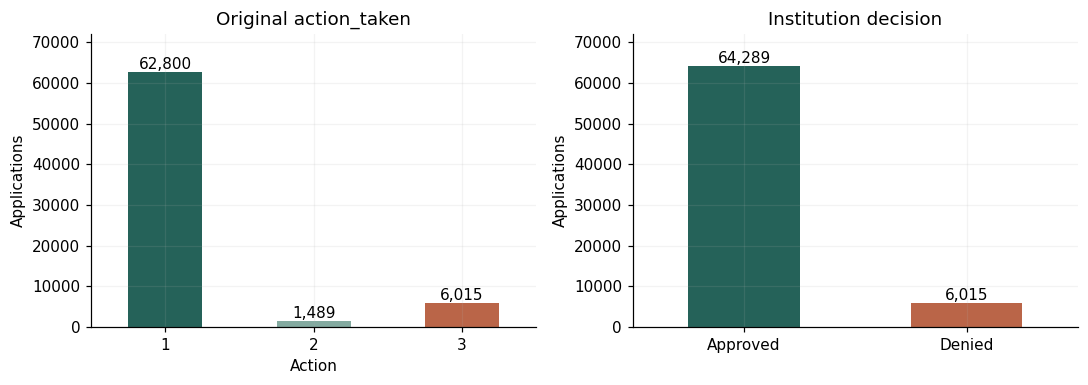

In [ ]:
action_summary = df["action_taken"].value_counts().sort_index().to_frame("건수")
action_summary["비율_pct"] = action_summary["건수"] / len(df) * 100
action_summary["의미"] = ["실행", "승인 후 미수락", "거절"]
display(action_summary)

# df에 새 열을 넣지 않고 별도 Series를 만든다.
decision = df["action_taken"].map({1: "Approved", 2: "Approved", 3: "Denied"})
decision.name = "decision"
target_summary = decision.value_counts().reindex(["Approved", "Denied"]).to_frame("건수")
target_summary["비율_pct"] = target_summary["건수"] / len(df) * 100
display(target_summary)
baseline_denial = target_summary.loc["Denied", "비율_pct"]
imbalance_ratio = target_summary.loc["Approved", "건수"] / target_summary.loc["Denied", "건수"]
print("승인:거절 =", round(imbalance_ratio, 3), ": 1")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
action_summary["건수"].plot.bar(ax=axes[0], color=["#256259", "#83aaa0", "#ba6548"], rot=0)
axes[0].set(title="Original action_taken", xlabel="Action", ylabel="Applications")
target_summary["건수"].plot.bar(ax=axes[1], color=["#256259", "#ba6548"], rot=0)
axes[1].set(title="Institution decision", xlabel="", ylabel="Applications")
for ax in axes:
    for bar in ax.patches:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                f"{bar.get_height():,.0f}", ha="center", va="bottom")
    ax.set_ylim(0, 72000)
plt.tight_layout()
plt.show()

**실제 결과:** 실행 62,800건(89.33%), 승인 후 미수락 1,489건(2.12%), 거절 6,015건(8.56%). 승인 합계는 **62,800 + 1,489 = 64,289건**, 승인률은 **64,289 ÷ 70,304 × 100 = 91.44%**이다. 거절률은 **6,015 ÷ 70,304 × 100 = 8.56%**, 승인:거절은 **10.69:1**이다.

**의미:** 이후 전부 승인으로만 분류해도 이 표본에서 정확도 91.44%가 된다는 계산이다. 실제 예측모형을 학습한 결과가 아니다. 다음 모델링에서는 이 기준과 함께 거절 재현율·정밀도 등을 봐야 한다. Action 2를 거절로 넣으면 금융기관 승인과 신청자의 수락을 혼동한다. [Action 정의](https://ffiec.cfpb.gov/documentation/publications/loan-level-datasets/lar-data-fields#action_taken)

## ③ 결측치·특수값 현황
### 3-1. 원문과 NaN을 구분한 17변수 점검표
`df.isna()`만으로는 `Exempt`, 8888, Not Available 등을 찾을 수 없다. 원문 빈칸·`NA`·면제·코드·정보 비가용·자유서술만 존재하는 범주를 각각 센다.

- `NA`: 해당 필드 보고가 적용되지 않는 경우 등을 나타내는 HMDA 표기. 발생 이유를 일반적인 무응답으로 단정하지 않는다.
- `Exempt`: 해당 필드 보고 면제에 따른 표기. 숫자 0이 아니다.
- `8888`: 신청자 나이 보고의 해당 없음 코드.
- `Not Available`: 집계 정보 비가용 범주.
- `Free Form Text Only`: 공개된 분류 정보가 자유서술만으로 표시된 범주. **단순 결측과 동일하지 않다.**

출처: [2025 FIG: 소득·연령·DTI 등](https://ffiec.cfpb.gov/documentation/fig/2025/overview), [공개 인구학적 범주](https://ffiec.cfpb.gov/documentation/publications/loan-level-datasets/lar-data-fields#derived_race).

In [ ]:
missing_summary = pd.DataFrame(index=selected_columns)
missing_summary["df_NaN"] = df.isna().sum()
missing_summary["원문빈칸"] = df_text.eq("").sum()
missing_summary["원문NA"] = df_text.eq("NA").sum()
missing_summary["Exempt"] = df_text.eq("Exempt").sum()
missing_summary["나이8888"] = 0
missing_summary.loc["applicant_age", "나이8888"] = df_text["applicant_age"].eq("8888").sum()
not_available = ["Sex Not Available", "Race Not Available", "Ethnicity Not Available"]
missing_summary["NotAvailable"] = df_text.isin(not_available).sum()
missing_summary["FreeTextOnly"] = df_text.eq("Free Form Text Only").sum()
other_tokens = ["N/A", "NaN", "nan", "NULL", "null", "None", "-"]
missing_summary["기타미기재표기"] = df_text.isin(other_tokens).sum()

special_tokens = ["", "NA", "Exempt", "Free Form Text Only"] + not_available + other_tokens
special_mask = df_text.isin(special_tokens)
special_mask["applicant_age"] = special_mask["applicant_age"] | df_text["applicant_age"].eq("8888")
missing_summary["원문특수합계"] = special_mask.sum()
missing_summary["특수비율_pct"] = special_mask.mean() * 100
# 각 종류의 셀에 건수와 전체 대비 비율을 함께 표시한다.
missing_display = pd.DataFrame(index=selected_columns)
for col in missing_summary.columns[:-1]:
    counts = missing_summary[col].astype(int)
    percents = (counts / len(df) * 100).round(2)
    missing_display[col] = counts.astype(str) + " (" + percents.astype(str) + "%)"
display(missing_display)

# 원문을 새 값으로 바꾸지 않고, 실제 특수값의 종류·건수도 확인한다.
for col in selected_columns:
    observed_specials = df_text.loc[special_mask[col], col].value_counts(dropna=False)
    if len(observed_specials) > 0:
        print(col, observed_specials.to_dict())

print("원문 문자열 앞뒤 공백 수:")
for col in selected_columns:
    print(col, df_text[col].ne(df_text[col].str.strip()).sum())

,df_NaN,원문빈칸,원문NA,Exempt,나이8888,NotAvailable,FreeTextOnly,기타미기재표기,원문특수합계
action_taken,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)
income,4426 (6.3%),0 (0.0%),4426 (6.3%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),4426 (6.3%)
loan_amount,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)
debt_to_income_ratio,3869 (5.5%),0 (0.0%),3869 (5.5%),4333 (6.16%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),8202 (11.67%)
loan_to_value_ratio,1179 (1.68%),0 (0.0%),1179 (1.68%),4333 (6.16%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),5512 (7.84%)
property_value,563 (0.8%),0 (0.0%),563 (0.8%),4332 (6.16%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),4895 (6.96%)
loan_term,78 (0.11%),0 (0.0%),78 (0.11%),4333 (6.16%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),4411 (6.27%)
loan_type,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)
lien_status,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)
occupancy_type,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)


income {'NA': 4426}
debt_to_income_ratio {'Exempt': 4333, 'NA': 3869}
loan_to_value_ratio {'Exempt': 4333, 'NA': 1179}
property_value {'Exempt': 4332, 'NA': 563}
loan_term {'Exempt': 4333, 'NA': 78}
county_code {'NA': 266}
applicant_age {'8888': 2969}
derived_sex {'Sex Not Available': 6167}
derived_race {'Race Not Available': 12424, 'Free Form Text Only': 14}
derived_ethnicity {'Ethnicity Not Available': 11262, 'Free Form Text Only': 30}
원문 문자열 앞뒤 공백 수:
action_taken 0
income 0
loan_amount 0
debt_to_income_ratio 0
loan_to_value_ratio 0
property_value 0
loan_term 0
loan_type 0
lien_status 0
occupancy_type 0
county_code 0
applicant_age 0
derived_sex 0
derived_race 0
derived_ethnicity 0
preapproval 0
total_units 0


**해석:** 표의 각 셀은 **건수(전체 대비 %)**이다. `df_NaN`과 `원문NA`는 중복되는 집계이며 더하지 않는다. 원문 특수합계는 행별 Boolean으로 계산해 중복을 피했다. 원문 빈칸·기타미기재표기·앞뒤 공백은 모두 0건이다. 따라서 현재 파일에서 기본 읽기의 NaN은 원문의 `NA`에 대응한다.

- DTI: NA 3,869건 + Exempt 4,333건 = **8,202건(11.67%)**.
- CLTV: NA 1,179건 + Exempt 4,333건 = **5,512건(7.84%)**.
- 부동산 가치: NA 563건 + Exempt 4,332건 = **4,895건(6.96%)**.
- 소득: NA **4,426건(6.30%)**. 대출기간: NA 78건 + Exempt 4,333건 = **4,411건(6.27%)**.
- County: NA 266건(0.38%). 나이 8888: 2,969건(4.22%).
- 성별 Not Available 6,167건(8.77%), 인종 Not Available 12,424건(17.67%)과 Free Text 14건(0.02%), ethnicity Not Available 11,262건(16.02%)과 Free Text 30건(0.04%). 인종·ethnicity의 표시 정보 부족이 특히 크다.
- 타깃·대출금액·대출유형·담보순위·이용목적·사전승인요청·주거단위수에는 이 표의 결측·특수값이 없다.

**판단:** 이 수치들을 모두 같은 종류의 결측률로 부르지 않는다. 어떤 정보가 없거나 공개 분류가 어려운지를 구분한 점검표이다. 원문을 유지한 채 다음 단계에서 변수별 원인을 확인해야 한다.

### 3-2. 같은 행에서의 동시 발생
몇 개 열이 함께 비어 있는지, 보고 면제가 여러 열에서 함께 나타나는지 확인한다. 결측이 있다고 그 행을 제거하지 않는다.

In [ ]:
special_count = special_mask.sum(axis=1)
display(special_count.value_counts().sort_index().to_frame("신청건수"))
print("특수값이 하나 이상인 행:", special_count.gt(0).sum())
print("전체 대비 비율(%):", special_count.gt(0).mean() * 100)

core_special = special_mask[["income", "debt_to_income_ratio", "loan_to_value_ratio",
                             "property_value", "loan_term"]]
print("핵심 5개 중 하나 이상 숫자/구간정보가 없는 행:", core_special.any(axis=1).sum())
print("핵심 5개 동시 패턴 상위 10개 (True=특수값):")
display(core_special.value_counts().head(10).to_frame("건수"))

exempt_columns = ["debt_to_income_ratio", "loan_to_value_ratio", "property_value", "loan_term"]
exempt_pattern = df_text[exempt_columns].eq("Exempt")
display(exempt_pattern.value_counts().to_frame("건수"))
print("소득 NA × 나이 8888:")
display(pd.crosstab(df_text["income"].eq("NA"),
                    df_text["applicant_age"].eq("8888"),
                    rownames=["income_NA"], colnames=["age_8888"]))

,신청건수
0,50548
1,5740
2,4494
3,2732
4,3091
5,372
6,1908
7,360
8,69
9,990


특수값이 하나 이상인 행: 19756
전체 대비 비율(%): 28.10081929904415
핵심 5개 중 하나 이상 숫자/구간정보가 없는 행: 9497
핵심 5개 동시 패턴 상위 10개 (True=특수값):


건수
income debt_to_income_ratio loan_to_value_ratio property_value loan_term       
False  False                False               False          False      60807
       True                 True                True           True        3395
True   True                 False               False          False       2782
                            True                True           True         946
False  True                 False               False          False        676
       False                True                False          False        623
True   False                False               False          False        364
       True                 True                True           False        239
False  False                True                True           False        152
                            False               True           False        104

건수
debt_to_income_ratio loan_to_value_ratio property_value loan_term       
False                False               False          False      65971
True                 True                True           True        4332
                                         False          True           1

소득 NA × 나이 8888:


age_8888,False,True
income_NA,,
False,65865,13
True,1470,2956


**해석:** 17개 중 특수표기가 하나 이상인 행은 **19,756건(28.10%)**이다. 여기에는 정보 비가용·자유서술 등도 포함된다. 핵심 5개만 보면 하나 이상 NA/Exempt인 행은 **9,497건(13.51%)**이다. 이 비율은 실제 삭제율이 아니라, 모든 핵심 필드가 관측되어야 한다고 가정할 때 제외될 수 있는 규모를 점검한 값이다.

DTI·CLTV·부동산가치·대출기간이 **모두 Exempt인 행은 4,332건**이다. DTI·CLTV·기간만 Exempt이고 부동산가치는 그렇지 않은 행이 1건 더 있다. 또한 연령 8888인 2,969건 중 소득 NA는 2,956건이다. 정보 부재가 여러 열에 함께 나타난다. 이 패턴만으로 MCAR/MAR/MNAR를 확정할 수 없으며, 동일 기관이나 동일 상품 때문인지도 이 17개 열만으로 확인할 수 없다.

### 3-3. 관측값/NA/Exempt별 거절률
결측·면제와 타깃이 연관되는지 확인한다. 아래 Observed는 기존에 실제 값 또는 DTI 구간이 있는 경우이며, **NA를 관측값으로 대치하는 작업이 아니다.** status는 비교표를 위한 별도 Series다.

In [ ]:
status_tables = []
for col in ["income", "debt_to_income_ratio", "loan_to_value_ratio", "property_value", "loan_term", "county_code"]:
    status = pd.Series("Observed", index=df.index, name="status")
    status.loc[df_text[col].eq("NA")] = "NA"
    status.loc[df_text[col].eq("Exempt")] = "Exempt"
    tab = pd.crosstab(status, decision)
    tab = tab.reindex(columns=["Approved", "Denied"], fill_value=0)
    tab["신청건수"] = tab["Approved"] + tab["Denied"]
    tab["거절률_pct"] = tab["Denied"] / tab["신청건수"] * 100
    tab["변수"] = col
    status_tables.append(tab.reset_index())
status_summary = pd.concat(status_tables, ignore_index=True)
display(status_summary[["변수", "status", "신청건수", "Approved", "Denied", "거절률_pct"]])

decision,변수,status,신청건수,Approved,Denied,거절률_pct
0,income,NA,4426,3991,435,9.828
1,income,Observed,65878,60298,5580,8.470
2,debt_to_income_ratio,Exempt,4333,4059,274,6.324
3,debt_to_income_ratio,NA,3869,3346,523,13.518
4,debt_to_income_ratio,Observed,62102,56884,5218,8.402
5,loan_to_value_ratio,Exempt,4333,4059,274,6.324
6,loan_to_value_ratio,NA,1179,798,381,32.316
7,loan_to_value_ratio,Observed,64792,59432,5360,8.273
8,property_value,Exempt,4332,4058,274,6.325
9,property_value,NA,563,212,351,62.345


**해석:** 부동산가치 NA는 **351/563 = 62.34%**, 기간 NA는 **54/78 = 69.23%**, CLTV NA는 **381/1,179 = 32.32%**, County NA는 **98/266 = 36.84%**가 거절이다. 관측값 집단보다 높은 경우가 있으며, Exempt 집단(대체로 6.32%)과도 성격이 다르다. 소득 NA는 9.83%, DTI NA는 13.52%이다.

**다음 단계 연결:** 단순 완전사례 분석은 거절 사례를 상대적으로 많이 잃을 수 있다. 반대로 NA 여부를 예측변수로 쓰면 실제 신청 시점에 알 수 있던 정보인지 점검해야 한다. 심사 결과·진행 과정 때문에 보고값이 없어진 경우라면 결과를 미리 아는 정보가 될 수 있다. 현재 EDA만으로 그 시점을 확인할 수 없으므로 바로 예측변수로 채택하지 않는다.

## ④ 핵심 변수별 단변량 EDA
### 4-1. 수치형: 전체 분포와 중심부를 함께 보기
각 절의 첫 히스토그램·상자그림은 **모든 숫자값**을 포함한다. 세 번째 패널은 1~99백분위 구간만 확대해 보며 범위 밖 건수를 출력한다. 그래프 확대는 df의 제거·윈저화·대치가 아니다. IQR 후보는 분포 점검용이며 오류 판정 기준이 아니다.

### 4-1-1. `income`
기초통계·꼬리·극단값을 확인한다. 숫자로 변환할 수 없는 값은 임시 Series에서만 NaN이 되며, 원본과 `df`는 그대로다.

숫자 관측: 65878 변환 불가: 4426


,income
count,"65,878.000"
mean,216.824
std,369.270
min,"-7,407.000"
1%,21.000
25%,104.000
50%,153.000
75%,240.000
95%,514.000
99%,"1,113.000"


표본 왜도: 25.991006725766898
IQR 후보 경계: -100.0 444.0
IQR 경계 밖 건수: 4654
중심부 확대 범위: 21.0 1113.0
확대 범위 밖 숫자 건수: 1313


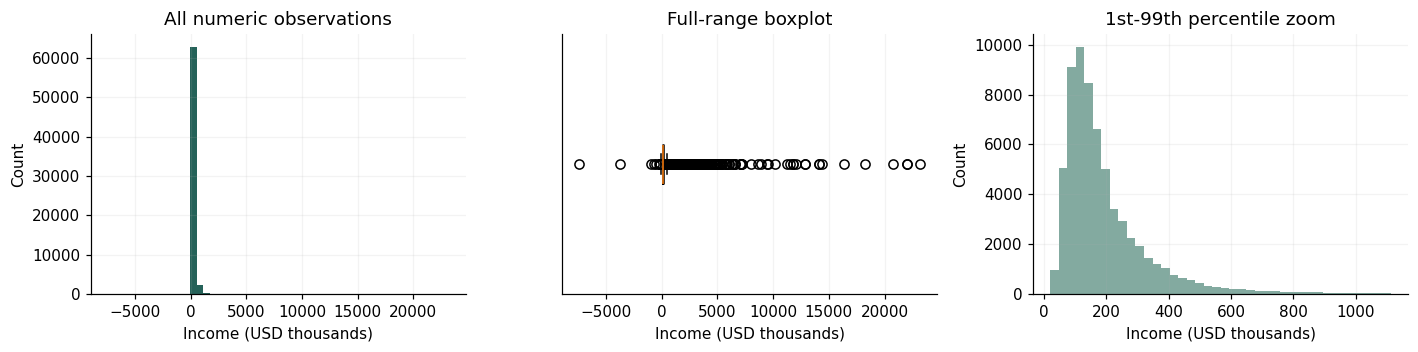

In [ ]:
s = pd.to_numeric(df["income"], errors="coerce")
print("숫자 관측:", s.notna().sum(), "변환 불가:", s.isna().sum())
display(s.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.95, 0.99]).to_frame("income"))
print("표본 왜도:", s.skew())
q1 = s.quantile(0.25)
q3 = s.quantile(0.75)
iqr = q3 - q1
low_fence = q1 - 1.5 * iqr
high_fence = q3 + 1.5 * iqr
print("IQR 후보 경계:", low_fence, high_fence)
print("IQR 경계 밖 건수:", ((s < low_fence) | (s > high_fence)).sum())
zoom_low = s.quantile(0.01)
zoom_high = s.quantile(0.99)
print("중심부 확대 범위:", zoom_low, zoom_high)
print("확대 범위 밖 숫자 건수:", ((s < zoom_low) | (s > zoom_high)).sum())

fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
axes[0].hist(s[s.notna()], bins=50, color="#256259")
axes[0].set(title="All numeric observations", xlabel="Income (USD thousands)", ylabel="Count")
axes[1].boxplot(s[s.notna()], vert=False, showfliers=True)
axes[1].set(title="Full-range boxplot", xlabel="Income (USD thousands)", yticks=[])
zoom = s[s.between(zoom_low, zoom_high)]
axes[2].hist(zoom, bins=40, color="#83aaa0")
axes[2].set(title="1st-99th percentile zoom", xlabel="Income (USD thousands)", ylabel="Count")
plt.tight_layout()
plt.show()

**실제 결과와 해석:** 소득은 평균 216.824천 USD, 중앙값 153천 USD이고 99백분위는 1,113천 USD다. 최대 23,170천 USD(23,170,000 USD), 최저 -7,407천 USD이며 오른쪽 꼬리가 길다. 음수 32건·0 소득 511건이 존재한다. HMDA는 음수 소득 보고를 허용하므로 음수를 곧바로 입력 오류로 단정하지 않는다. 반올림·심사상 소득 정의도 고려해야 하며, 개별 기록이 타당한지는 확인할 수 없다. 양수 부분의 로그변환을 나중에 검토할 수 있지만, 0·음수를 포함하는 전체 소득에 로그를 바로 적용하면 안 된다.

정의 확인: [2025 FIG](https://ffiec.cfpb.gov/documentation/fig/2025/overview).

### 4-1-2. `loan_amount`
기초통계·꼬리·극단값을 확인한다. 숫자로 변환할 수 없는 값은 임시 Series에서만 NaN이 되며, 원본과 `df`는 그대로다.

숫자 관측: 70304 변환 불가: 0


,loan_amount
count,"70,304.000"
mean,"593,895.938"
std,"1,355,491.794"
min,"5,000.000"
1%,"25,000.000"
25%,"315,000.000"
50%,"475,000.000"
75%,"665,000.000"
95%,"1,255,000.000"
99%,"2,494,700.000"


표본 왜도: 46.36184346822393
IQR 후보 경계: -210000.0 1190000.0
IQR 경계 밖 건수: 4063
중심부 확대 범위: 25000.0 2494700.0000000116
확대 범위 밖 숫자 건수: 996


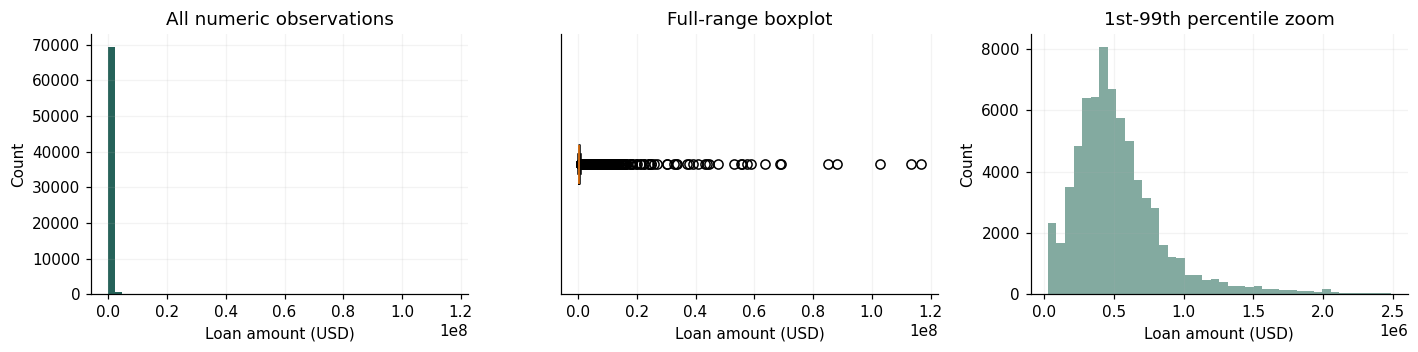

In [ ]:
s = pd.to_numeric(df["loan_amount"], errors="coerce")
print("숫자 관측:", s.notna().sum(), "변환 불가:", s.isna().sum())
display(s.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.95, 0.99]).to_frame("loan_amount"))
print("표본 왜도:", s.skew())
q1 = s.quantile(0.25)
q3 = s.quantile(0.75)
iqr = q3 - q1
low_fence = q1 - 1.5 * iqr
high_fence = q3 + 1.5 * iqr
print("IQR 후보 경계:", low_fence, high_fence)
print("IQR 경계 밖 건수:", ((s < low_fence) | (s > high_fence)).sum())
zoom_low = s.quantile(0.01)
zoom_high = s.quantile(0.99)
print("중심부 확대 범위:", zoom_low, zoom_high)
print("확대 범위 밖 숫자 건수:", ((s < zoom_low) | (s > zoom_high)).sum())

fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
axes[0].hist(s[s.notna()], bins=50, color="#256259")
axes[0].set(title="All numeric observations", xlabel="Loan amount (USD)", ylabel="Count")
axes[1].boxplot(s[s.notna()], vert=False, showfliers=True)
axes[1].set(title="Full-range boxplot", xlabel="Loan amount (USD)", yticks=[])
zoom = s[s.between(zoom_low, zoom_high)]
axes[2].hist(zoom, bins=40, color="#83aaa0")
axes[2].set(title="1st-99th percentile zoom", xlabel="Loan amount (USD)", ylabel="Count")
plt.tight_layout()
plt.show()

**실제 결과와 해석:** 대출금액 중앙값 475,000 USD, 평균 약 593,896 USD, 99백분위 2,494,700 USD다. 최소 5,000 USD·최대 116,755,000 USD이며 큰 금액이 꼬리를 늘린다. 10,000,000 USD 초과는 84건이다. 공개 금액은 10,000달러 구간의 중간값이므로 5,000 USD를 실제 정확한 계약금액으로 읽지 않는다. Home Purchase만으로 개인의 일반 단독주택 대출로 범위가 제한되지는 않는다. 초고액을 바로 제거하지 않고 대상 부동산·상품 범위를 확인할 필요가 있다.

공개 금액 처리 출처: [CFPB 공개 정책](https://www.federalregister.gov/documents/2019/01/31/2018-28404/disclosure-of-loan-level-hmda-data).

### 4-1-3. `property_value`
기초통계·꼬리·극단값을 확인한다. 숫자로 변환할 수 없는 값은 임시 Series에서만 NaN이 되며, 원본과 `df`는 그대로다.

숫자 관측: 65409 변환 불가: 4895


,property_value
count,"65,409.000"
mean,"868,976.670"
std,"7,596,608.390"
min,"45,000.000"
1%,"195,000.000"
25%,"445,000.000"
50%,"635,000.000"
75%,"885,000.000"
95%,"1,835,000.000"
99%,"3,505,000.000"


표본 왜도: 225.8698197460928
IQR 후보 경계: -215000.0 1545000.0
IQR 경계 밖 건수: 4796
중심부 확대 범위: 195000.0 3505000.0
확대 범위 밖 숫자 건수: 1260


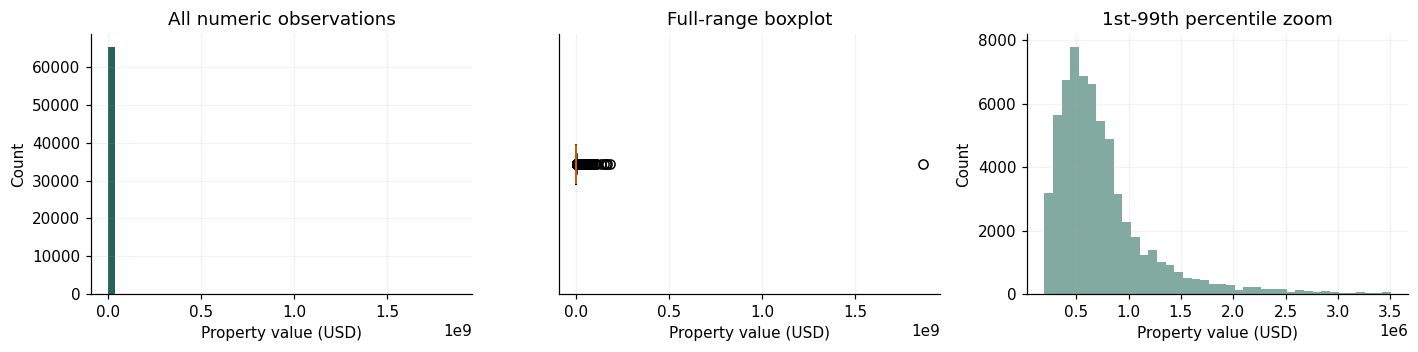

In [ ]:
s = pd.to_numeric(df["property_value"], errors="coerce")
print("숫자 관측:", s.notna().sum(), "변환 불가:", s.isna().sum())
display(s.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.95, 0.99]).to_frame("property_value"))
print("표본 왜도:", s.skew())
q1 = s.quantile(0.25)
q3 = s.quantile(0.75)
iqr = q3 - q1
low_fence = q1 - 1.5 * iqr
high_fence = q3 + 1.5 * iqr
print("IQR 후보 경계:", low_fence, high_fence)
print("IQR 경계 밖 건수:", ((s < low_fence) | (s > high_fence)).sum())
zoom_low = s.quantile(0.01)
zoom_high = s.quantile(0.99)
print("중심부 확대 범위:", zoom_low, zoom_high)
print("확대 범위 밖 숫자 건수:", ((s < zoom_low) | (s > zoom_high)).sum())

fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
axes[0].hist(s[s.notna()], bins=50, color="#256259")
axes[0].set(title="All numeric observations", xlabel="Property value (USD)", ylabel="Count")
axes[1].boxplot(s[s.notna()], vert=False, showfliers=True)
axes[1].set(title="Full-range boxplot", xlabel="Property value (USD)", yticks=[])
zoom = s[s.between(zoom_low, zoom_high)]
axes[2].hist(zoom, bins=40, color="#83aaa0")
axes[2].set(title="1st-99th percentile zoom", xlabel="Property value (USD)", ylabel="Count")
plt.tight_layout()
plt.show()

**실제 결과와 해석:** 부동산가치 중앙값 635,000 USD, 평균 약 868,977 USD, 99백분위 3,505,000 USD다. 최대 1,861,825,000 USD는 중심부에서 매우 멀며 평균과 Pearson 상관을 크게 바꿀 가능성이 있다. 10,000,000 USD 초과는 100건이다. 추가한 `total_units`를 확인하면 부동산가치 상위 5건은 모두 `>149` 구간이다. 150세대 이상 담보가 포함된 것은 확인되지만, 사업용·복합 담보 여부와 금액의 정확성은 이 값만으로 확정할 수 없다. 실제 오류인지 실제 고액 담보인지 보류하고, 해당 행을 ⑧에서 함께 확인한다.

공개 금액 처리 출처: [CFPB 공개 정책](https://www.federalregister.gov/documents/2019/01/31/2018-28404/disclosure-of-loan-level-hmda-data).

### 4-1-4. `loan_term`
기초통계·꼬리·극단값을 확인한다. 숫자로 변환할 수 없는 값은 임시 Series에서만 NaN이 되며, 원본과 `df`는 그대로다.

숫자 관측: 65893 변환 불가: 4411


,loan_term
count,"65,893.000"
mean,339.170
std,67.226
min,6.000
1%,12.000
25%,360.000
50%,360.000
75%,360.000
95%,360.000
99%,360.000


표본 왜도: -3.32295686440209
IQR 후보 경계: 360.0 360.0
IQR 경계 밖 건수: 8761
중심부 확대 범위: 12.0 360.0
확대 범위 밖 숫자 건수: 582


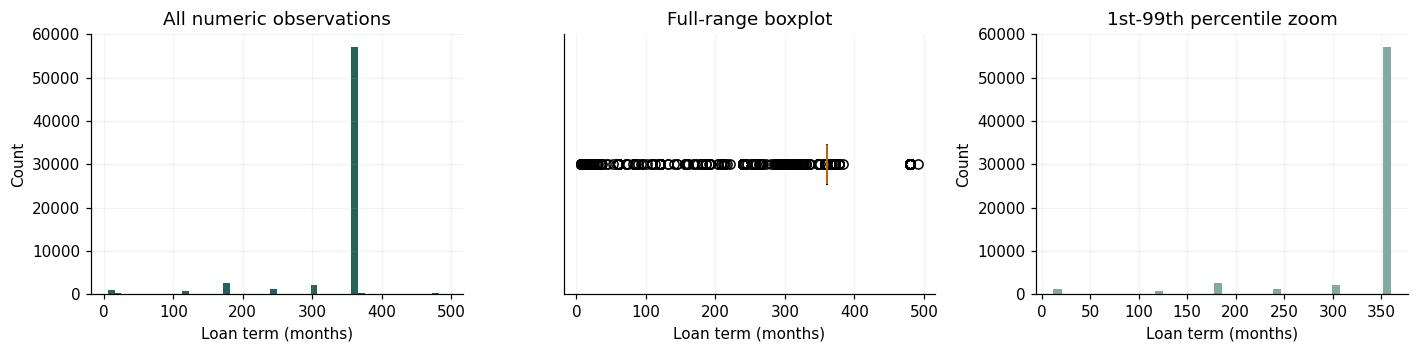

In [ ]:
s = pd.to_numeric(df["loan_term"], errors="coerce")
print("숫자 관측:", s.notna().sum(), "변환 불가:", s.isna().sum())
display(s.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.95, 0.99]).to_frame("loan_term"))
print("표본 왜도:", s.skew())
q1 = s.quantile(0.25)
q3 = s.quantile(0.75)
iqr = q3 - q1
low_fence = q1 - 1.5 * iqr
high_fence = q3 + 1.5 * iqr
print("IQR 후보 경계:", low_fence, high_fence)
print("IQR 경계 밖 건수:", ((s < low_fence) | (s > high_fence)).sum())
zoom_low = s.quantile(0.01)
zoom_high = s.quantile(0.99)
print("중심부 확대 범위:", zoom_low, zoom_high)
print("확대 범위 밖 숫자 건수:", ((s < zoom_low) | (s > zoom_high)).sum())

fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
axes[0].hist(s[s.notna()], bins=50, color="#256259")
axes[0].set(title="All numeric observations", xlabel="Loan term (months)", ylabel="Count")
axes[1].boxplot(s[s.notna()], vert=False, showfliers=True)
axes[1].set(title="Full-range boxplot", xlabel="Loan term (months)", yticks=[])
zoom = s[s.between(zoom_low, zoom_high)]
axes[2].hist(zoom, bins=40, color="#83aaa0")
axes[2].set(title="1st-99th percentile zoom", xlabel="Loan term (months)", ylabel="Count")
plt.tight_layout()
plt.show()

**실제 결과와 해석:** 숫자 기간의 25·50·75백분위가 모두 360개월이다. 360개월은 57,132건으로 전체의 81.26%, 숫자 관측 65,893건의 86.70%이다. 평균 339.17개월은 일부 짧은 기간의 영향을 받는다. 최소 6개월, 최대 492개월(41년)이고 12개월 미만 35건·360개월 초과 547건이다. IQR이 0이어서 360개월이 아닌 값 8,761건이 전부 IQR 후보가 된다. 이는 모두 오류라는 뜻이 아니라, 집중 분포에서 기계적 IQR 판정이 부적절하다는 사례다.

### 4-1-5. `loan_to_value_ratio`
기초통계·꼬리·극단값을 확인한다. 숫자로 변환할 수 없는 값은 임시 Series에서만 NaN이 되며, 원본과 `df`는 그대로다.

숫자 관측: 64792 변환 불가: 5512


,loan_to_value_ratio
count,"64,792.000"
mean,77.807
std,18.956
min,0.167
1%,18.518
25%,70.000
50%,80.000
75%,94.784
95%,100.000
99%,103.745


표본 왜도: -1.027327876937214
IQR 후보 경계: 32.824749999999995 131.95875
IQR 경계 밖 건수: 2177
중심부 확대 범위: 18.518189999999997 103.74453999999997
확대 범위 밖 숫자 건수: 1296


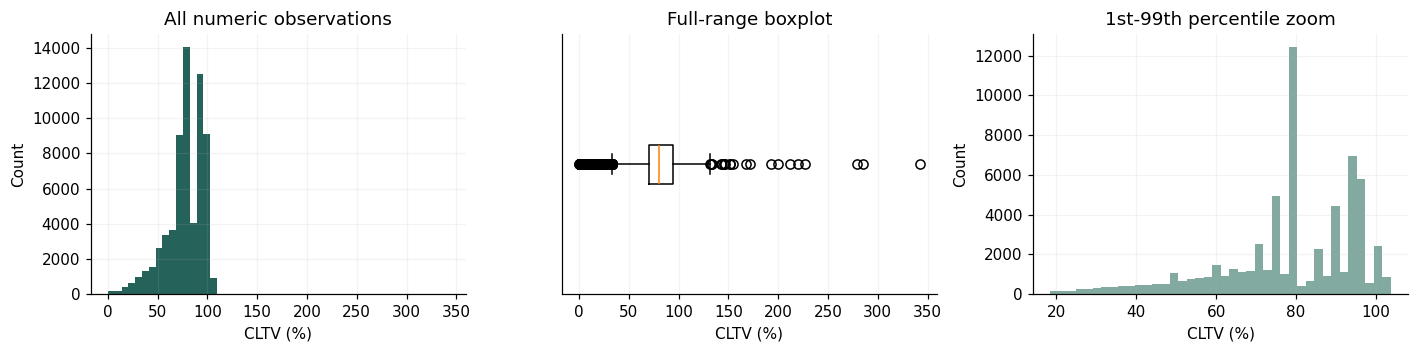

In [ ]:
s = pd.to_numeric(df["loan_to_value_ratio"], errors="coerce")
print("숫자 관측:", s.notna().sum(), "변환 불가:", s.isna().sum())
display(s.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.95, 0.99]).to_frame("loan_to_value_ratio"))
print("표본 왜도:", s.skew())
q1 = s.quantile(0.25)
q3 = s.quantile(0.75)
iqr = q3 - q1
low_fence = q1 - 1.5 * iqr
high_fence = q3 + 1.5 * iqr
print("IQR 후보 경계:", low_fence, high_fence)
print("IQR 경계 밖 건수:", ((s < low_fence) | (s > high_fence)).sum())
zoom_low = s.quantile(0.01)
zoom_high = s.quantile(0.99)
print("중심부 확대 범위:", zoom_low, zoom_high)
print("확대 범위 밖 숫자 건수:", ((s < zoom_low) | (s > zoom_high)).sum())

fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
axes[0].hist(s[s.notna()], bins=50, color="#256259")
axes[0].set(title="All numeric observations", xlabel="CLTV (%)", ylabel="Count")
axes[1].boxplot(s[s.notna()], vert=False, showfliers=True)
axes[1].set(title="Full-range boxplot", xlabel="CLTV (%)", yticks=[])
zoom = s[s.between(zoom_low, zoom_high)]
axes[2].hist(zoom, bins=40, color="#83aaa0")
axes[2].set(title="1st-99th percentile zoom", xlabel="CLTV (%)", ylabel="Count")
plt.tight_layout()
plt.show()

**실제 결과와 해석:** CLTV 중앙값은 80%, 사분위 범위는 70~94.7835%, 평균은 77.807%다. 소득·금액과 달리 표본 왜도는 음수이며 낮은 비율 쪽 꼬리도 존재한다. 최대 342.188%, 100% 초과 2,241건·150% 초과 13건이다. 100% 초과를 무조건 오류로 볼 수는 없고 담보 총부채가 심사 가치보다 클 가능성 등을 검토해야 한다. DTI와 달리 숫자로 공개되어 있어 연속형 비교가 가능하다. 다만 NA/Exempt인 5,512건은 이 숫자 통계의 분모에서 빠진다.

### 4-2. 범주·구간형 분포
빈도와 전체 대비 비율을 본다. 희귀범주 점검 표시는 **100건 미만 또는 전체 0.5% 미만**으로 둔다. 이 기준은 이 노트북의 탐색용 표시일 뿐 공식 기준이나 범주 병합 지시가 아니다. DTI는 크기 순서대로 정렬하되 원문 구간을 숫자 중간값으로 바꾸지 않는다.

### 4-2-1. `debt_to_income_ratio` 빈도·비율
주요 범주와 드문 범주를 확인해 비교 결과의 분모를 이해한다.

In [ ]:
frequency = df_text["debt_to_income_ratio"].value_counts(dropna=False)
frequency = frequency.reindex(['<20%', '20%-<30%', '30%-<36%', '36', '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47', '48', '49', '50%-60%', '>60%', 'NA', 'Exempt'])
frequency = frequency.to_frame("건수")
frequency["비율_pct"] = frequency["건수"] / len(df) * 100
frequency["희귀_점검"] = (frequency["건수"] < 100) | (frequency["비율_pct"] < 0.5)
display(frequency)

,건수,비율_pct,희귀_점검
debt_to_income_ratio,,,
<20%,2487,3.537,False
20%-<30%,8241,11.722,False
30%-<36%,9480,13.484,False
36,1964,2.794,False
37,2106,2.996,False
38,2189,3.114,False
39,2337,3.324,False
40,2533,3.603,False
41,2579,3.668,False


**해석:** DTI의 최빈 구간은 30%-<36%(9,480건·13.48%)이고 다음은 20%-<30%(8,241건·11.72%)다. 50%-60%는 4,668건(6.64%), >60%는 1,956건(2.78%)이다. Exempt 4,333건과 NA 3,869건은 수치의 크기 순서에 넣지 않는다. 숫자처럼 보이는 36~49와 구간이 혼재하므로 범주로 유지한다. 공개 라벨의 경계 표기는 원문 그대로 사용하며 원래 정밀값을 복원하지 않는다.

### 4-2-2. `loan_type` 빈도·비율
주요 범주와 드문 범주를 확인해 비교 결과의 분모를 이해한다.

In [ ]:
frequency = df_text["loan_type"].value_counts(dropna=False)
frequency = frequency.to_frame("건수")
frequency["비율_pct"] = frequency["건수"] / len(df) * 100
frequency["희귀_점검"] = (frequency["건수"] < 100) | (frequency["비율_pct"] < 0.5)
display(frequency)

,건수,비율_pct,희귀_점검
loan_type,,,
1,61414,87.355,False
2,6446,9.169,False
3,2175,3.094,False
4,269,0.383,True


**해석:** Conventional(1)은 61,414건(87.35%)으로 압도적이다. FHA 6,446건(9.17%), VA 2,175건(3.09%), RHS/FSA 269건(0.38%)이다. 4번의 작은 비중은 정부 보증 대출 전반이 적다는 뜻과 구분한다. 상품에 따라 신청자 구성이 달라질 수 있어 승인/거절과 함께 볼 필요가 있다.

### 4-2-3. `lien_status` 빈도·비율
주요 범주와 드문 범주를 확인해 비교 결과의 분모를 이해한다.

In [ ]:
frequency = df_text["lien_status"].value_counts(dropna=False)
frequency = frequency.to_frame("건수")
frequency["비율_pct"] = frequency["건수"] / len(df) * 100
frequency["희귀_점검"] = (frequency["건수"] < 100) | (frequency["비율_pct"] < 0.5)
display(frequency)

,건수,비율_pct,희귀_점검
lien_status,,,
1,65623,93.342,False
2,4681,6.658,False


**해석:** 선순위(1)는 65,623건(93.34%), 후순위(2)는 4,681건(6.66%)이다. 후순위는 적지만 거절률을 비교할 수 있는 기록이 존재한다. 코드 2를 정확한 두 번째 순위라고 해석하지 않는다.

### 4-2-4. `occupancy_type` 빈도·비율
주요 범주와 드문 범주를 확인해 비교 결과의 분모를 이해한다.

In [ ]:
frequency = df_text["occupancy_type"].value_counts(dropna=False)
frequency = frequency.to_frame("건수")
frequency["비율_pct"] = frequency["건수"] / len(df) * 100
frequency["희귀_점검"] = (frequency["건수"] < 100) | (frequency["비율_pct"] < 0.5)
display(frequency)

,건수,비율_pct,희귀_점검
occupancy_type,,,
1,60255,85.706,False
3,7905,11.244,False
2,2144,3.050,False


**해석:** 주거주(1) 60,255건(85.71%), 투자용(3) 7,905건(11.24%), 제2주택(2) 2,144건(3.05%)이다. 주거주 대출이 중심이지만 투자용을 포함한 표본이므로 일반 실거주 구입 대출로만 해석하지 않는다.

### 4-2-5. `applicant_age` 빈도·비율
주요 범주와 드문 범주를 확인해 비교 결과의 분모를 이해한다.

In [ ]:
frequency = df_text["applicant_age"].value_counts(dropna=False)
frequency = frequency.reindex(['<25', '25-34', '35-44', '45-54', '55-64', '65-74', '>74', '8888'])
frequency = frequency.to_frame("건수")
frequency["비율_pct"] = frequency["건수"] / len(df) * 100
frequency["희귀_점검"] = (frequency["건수"] < 100) | (frequency["비율_pct"] < 0.5)
display(frequency)

,건수,비율_pct,희귀_점검
applicant_age,,,
<25,1921,2.732,False
25-34,21289,30.281,False
35-44,20376,28.983,False
45-54,11276,16.039,False
55-64,7841,11.153,False
65-74,3677,5.230,False
>74,955,1.358,False
8888,2969,4.223,False


**해석:** 25~34세 21,289건(30.28%)과 35~44세 20,376건(28.98%)를 합하면 41,665건(59.26%)이다. 75세 이상에 대응하는 >74 범주는 955건(1.36%)이며 8888은 2,969건(4.22%)이다. 8888을 연령의 최댓값이나 초고령으로 간주하면 안 된다.

### 4-2-6. `derived_sex` 빈도·비율
주요 범주와 드문 범주를 확인해 비교 결과의 분모를 이해한다.

In [ ]:
frequency = df_text["derived_sex"].value_counts(dropna=False)
frequency = frequency.to_frame("건수")
frequency["비율_pct"] = frequency["건수"] / len(df) * 100
frequency["희귀_점검"] = (frequency["건수"] < 100) | (frequency["비율_pct"] < 0.5)
display(frequency)

,건수,비율_pct,희귀_점검
derived_sex,,,
Joint,29176,41.500,False
Male,20402,29.020,False
Female,14559,20.709,False
Sex Not Available,6167,8.772,False


**해석:** Joint가 29,176건(41.50%)으로 가장 많다. Male 20,402건(29.02%), Female 14,559건(20.71%), Sex Not Available 6,167건(8.77%)이다. Joint는 신청자·공동신청자 정보를 집계한 결과이므로 개인 남성·여성만의 비교로 설명하지 않는다.

### 4-2-7. `derived_race` 빈도·비율
주요 범주와 드문 범주를 확인해 비교 결과의 분모를 이해한다.

In [ ]:
frequency = df_text["derived_race"].value_counts(dropna=False)
frequency = frequency.to_frame("건수")
frequency["비율_pct"] = frequency["건수"] / len(df) * 100
frequency["희귀_점검"] = (frequency["건수"] < 100) | (frequency["비율_pct"] < 0.5)
display(frequency)

,건수,비율_pct,희귀_점검
derived_race,,,
White,43575,61.981,False
Race Not Available,12424,17.672,False
Asian,6972,9.917,False
Black or African American,4786,6.808,False
Joint,2101,2.988,False
American Indian or Alaska Native,208,0.296,True
2 or more minority races,150,0.213,True
Native Hawaiian or Other Pacific Islander,74,0.105,True
Free Form Text Only,14,0.020,True


**해석:** White는 43,575건(61.98%)이고 Race Not Available은 12,424건(17.67%)이다. Asian 6,972건, Black or African American 4,786건이다. Free Form Text Only 14건, Native Hawaiian or Other Pacific Islander 74건 등은 매우 작아 추후 거절률이 높아도 그대로 순위를 매기기 어렵다. 자유서술 분류를 특정 인종으로 추측하지 않는다.

### 4-2-8. `derived_ethnicity` 빈도·비율
주요 범주와 드문 범주를 확인해 비교 결과의 분모를 이해한다.

In [ ]:
frequency = df_text["derived_ethnicity"].value_counts(dropna=False)
frequency = frequency.to_frame("건수")
frequency["비율_pct"] = frequency["건수"] / len(df) * 100
frequency["희귀_점검"] = (frequency["건수"] < 100) | (frequency["비율_pct"] < 0.5)
display(frequency)

,건수,비율_pct,희귀_점검
derived_ethnicity,,,
Not Hispanic or Latino,50169,71.360,False
Ethnicity Not Available,11262,16.019,False
Hispanic or Latino,7053,10.032,False
Joint,1790,2.546,False
Free Form Text Only,30,0.043,True


**해석:** Not Hispanic or Latino는 50,169건(71.36%), Hispanic or Latino는 7,053건(10.03%)이다. Ethnicity Not Available 11,262건(16.02%)으로 미제공·비가용 정보를 무시하기 어렵다. Free Form Text Only는 30건(0.04%)이다. ethnicity는 이 자료에서 Hispanic/Latino 계열의 구분이며 race를 대체하는 변수가 아니다.

### 4-2-9. `county_code` 빈도·비율
주요 범주와 드문 범주를 확인해 비교 결과의 분모를 이해한다.

In [ ]:
frequency = df_text["county_code"].value_counts(dropna=False)
frequency = frequency.to_frame("건수")
frequency["비율_pct"] = frequency["건수"] / len(df) * 100
frequency["희귀_점검"] = (frequency["건수"] < 100) | (frequency["비율_pct"] < 0.5)
display(frequency)

,건수,비율_pct,희귀_점검
county_code,,,
25017,15007,21.346,False
25027,9945,14.146,False
25009,7728,10.992,False
25021,7039,10.012,False
25025,6248,8.887,False
25023,6015,8.556,False
25005,5547,7.890,False
25013,5181,7.369,False
25001,3339,4.749,False


**해석:** 14개 County가 모두 관측된다. Middlesex에 해당하는 25017이 15,007건(21.35%)으로 가장 크고 25027은 9,945건(14.15%)이다. 25007은 230건, 25019는 216건이며 NA 266건은 County로 취급하지 않는다. 이름 매칭의 근거와 지역별 거절률은 ⑥에서 제시한다.

### 4-2-10. `preapproval` 빈도·비율
추가 변수의 분포와 희귀범주를 기존과 같은 기준으로 확인한다. 1은 사전승인 요청, 2는 미요청이다. [공식 정의](https://ffiec.cfpb.gov/documentation/publications/loan-level-datasets/lar-data-fields#preapproval)

In [ ]:
frequency = df_text["preapproval"].value_counts(dropna=False)
frequency = frequency.reindex(['1', '2'])
frequency = frequency.to_frame("건수")
frequency["비율_pct"] = frequency["건수"] / len(df) * 100
frequency["희귀_점검"] = (frequency["건수"] < 100) | (frequency["비율_pct"] < 0.5)
display(frequency)

,건수,비율_pct,희귀_점검
preapproval,,,
1,3609,5.133,False
2,66695,94.867,False


**해석:** 요청(1)은 **3,609/70,304 × 100 = 5.13%**, 미요청(2)은 **66,695/70,304 × 100 = 94.87%**다. 결측과 범위 밖 코드는 없다. 요청 여부이지 사전승인 통과 여부가 아니며, 숫자 코드의 평균을 계산할 의미는 없다.

### 4-2-11. `total_units` 빈도·비율
추가 변수의 분포와 희귀범주를 기존과 같은 기준으로 확인한다. 담보 부동산 관련 주거단위 수이며, 사람이 몇 명 사는지나 신청자의 가구원 수가 아니다. [공식 정의](https://ffiec.cfpb.gov/documentation/publications/loan-level-datasets/lar-data-fields#total_units)

In [ ]:
frequency = df_text["total_units"].value_counts(dropna=False)
frequency = frequency.reindex(['1', '2', '3', '4', '5-24', '25-49', '50-99', '100-149', '>149'])
frequency = frequency.to_frame("건수")
frequency["비율_pct"] = frequency["건수"] / len(df) * 100
frequency["희귀_점검"] = (frequency["건수"] < 100) | (frequency["비율_pct"] < 0.5)
display(frequency)

,건수,비율_pct,희귀_점검
total_units,,,
1,61836,87.955,False
2,4944,7.032,False
3,2192,3.118,False
4,552,0.785,False
5-24,648,0.922,False
25-49,58,0.082,True
50-99,44,0.063,True
100-149,9,0.013,True
>149,21,0.030,True


**해석:** 1세대 61,836건(87.96%), 2세대 4,944건(7.03%), 3세대 2,192건(3.12%), 4세대 552건(0.79%)이다. 5세대 이상 공개 구간 합계는 **648 + 58 + 44 + 9 + 21 = 780건(1.11%)**이다. `100-149`는 9건, `>149`는 21건 등으로 매우 작다. 범주가 9개라는 뜻이지 실제 주거단위 수가 최대 9개라는 뜻은 아니다. 구간을 임의 중간값으로 바꾸거나 숫자 변환 실패로 결측 처리하지 않는다.

## ⑤ 승인/거절과 각 변수의 관계
### 5-1. 수치형 변수의 그룹별 요약
평균·중앙값·사분위수와 관측 수를 같이 본다. 표본 수는 **해당 변수의 숫자 관측 수**이며, 두 그룹의 전체 건수와는 다를 수 있다. 아래 비교는 다른 특성을 통제하지 않은 관측 차이이다.

### 5-1-1. `income`: 평균·중앙값·상자그림
승인군과 거절군의 중심과 퍼짐을 비교한다. 전체 범위와 세로축 확대를 함께 표시해 극단값과 중심부를 모두 보존한다.

,count,mean,std,min,25%,50%,75%,max
decision,,,,,,,,
Approved,"60,298.000",221.448,364.185,"-3,775.000",108.000,157.000,246.000,"22,029.000"
Denied,"5,580.000",166.862,417.090,"-7,407.000",75.000,116.000,180.000,"23,170.000"


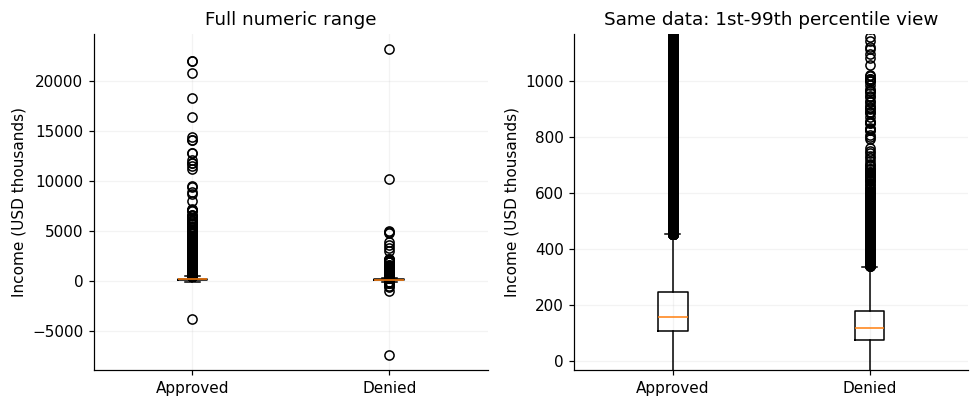

In [ ]:
s = pd.to_numeric(df["income"], errors="coerce")
group_summary = s.groupby(decision).describe()
group_summary = group_summary.reindex(["Approved", "Denied"])
display(group_summary)

approved_values = s[(decision == "Approved") & s.notna()]
denied_values = s[(decision == "Denied") & s.notna()]
zoom_low = s.quantile(0.01)
zoom_high = s.quantile(0.99)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax in axes:
    ax.boxplot([approved_values, denied_values], showfliers=True)
    ax.set_xticks([1, 2], ["Approved", "Denied"])
    ax.set_ylabel("Income (USD thousands)")
axes[0].set_title("Full numeric range")
axes[1].set_title("Same data: 1st-99th percentile view")
axes[1].set_ylim(zoom_low - (zoom_high-zoom_low)*0.05,
                 zoom_high + (zoom_high-zoom_low)*0.05)
plt.tight_layout()
plt.show()

**실제 결과와 해석:** 승인군 소득 중앙값은 157천 USD, 거절군은 116천 USD로 차이는 41천 USD(41,000 USD)다. 평균은 221.448천 USD 대 166.862천 USD, 사분위 범위는 108~246 대 75~180천 USD이다. 소득이 높은 쪽에 승인군이 분포하지만 두 분포는 상당히 겹친다. 숫자 소득이 관측된 건수는 승인 60,298건·거절 5,580건이므로 결측을 포함한 모든 신청자의 소득 차이라고 단정하지 않는다.

### 5-1-2. `loan_amount`: 평균·중앙값·상자그림
승인군과 거절군의 중심과 퍼짐을 비교한다. 전체 범위와 세로축 확대를 함께 표시해 극단값과 중심부를 모두 보존한다.

,count,mean,std,min,25%,50%,75%,max
decision,,,,,,,,
Approved,"64,289.000","604,000.762","1,405,742.413","5,000.000","325,000.000","485,000.000","675,000.000","116,755,000.000"
Denied,"6,015.000","485,894.431","584,522.605","5,000.000","235,000.000","405,000.000","605,000.000","26,005,000.000"


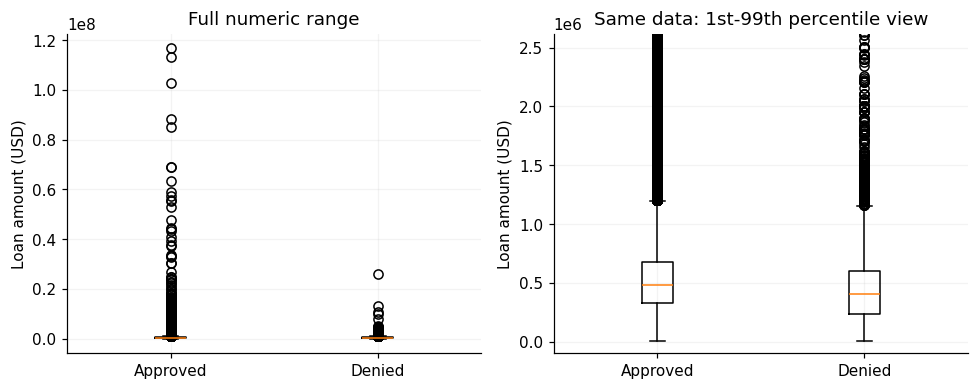

In [ ]:
s = pd.to_numeric(df["loan_amount"], errors="coerce")
group_summary = s.groupby(decision).describe()
group_summary = group_summary.reindex(["Approved", "Denied"])
display(group_summary)

approved_values = s[(decision == "Approved") & s.notna()]
denied_values = s[(decision == "Denied") & s.notna()]
zoom_low = s.quantile(0.01)
zoom_high = s.quantile(0.99)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax in axes:
    ax.boxplot([approved_values, denied_values], showfliers=True)
    ax.set_xticks([1, 2], ["Approved", "Denied"])
    ax.set_ylabel("Loan amount (USD)")
axes[0].set_title("Full numeric range")
axes[1].set_title("Same data: 1st-99th percentile view")
axes[1].set_ylim(zoom_low - (zoom_high-zoom_low)*0.05,
                 zoom_high + (zoom_high-zoom_low)*0.05)
plt.tight_layout()
plt.show()

**실제 결과와 해석:** 승인군 대출금액 중앙값은 485,000 USD, 거절군은 405,000 USD다. 평균도 약 604,001 대 485,894 USD로 승인군이 더 크다. “대출금액이 클수록 거절된다”는 단순한 예상과 맞지 않는다. 소득·담보가치·상품 구성이 다른 표본을 섞은 비교이므로 큰 대출금액이 승인을 유발한다고 해석하지 않는다. 소득·부동산가치와의 관계를 ⑦에서 확인한다.

### 5-1-3. `property_value`: 평균·중앙값·상자그림
승인군과 거절군의 중심과 퍼짐을 비교한다. 전체 범위와 세로축 확대를 함께 표시해 극단값과 중심부를 모두 보존한다.

,count,mean,std,min,25%,50%,75%,max
decision,,,,,,,,
Approved,"60,019.000","877,156.151","7,917,511.740","45,000.000","445,000.000","635,000.000","895,000.000","1,861,825,000.000"
Denied,"5,390.000","777,896.104","1,504,509.489","55,000.000","405,000.000","595,000.000","855,000.000","75,005,000.000"


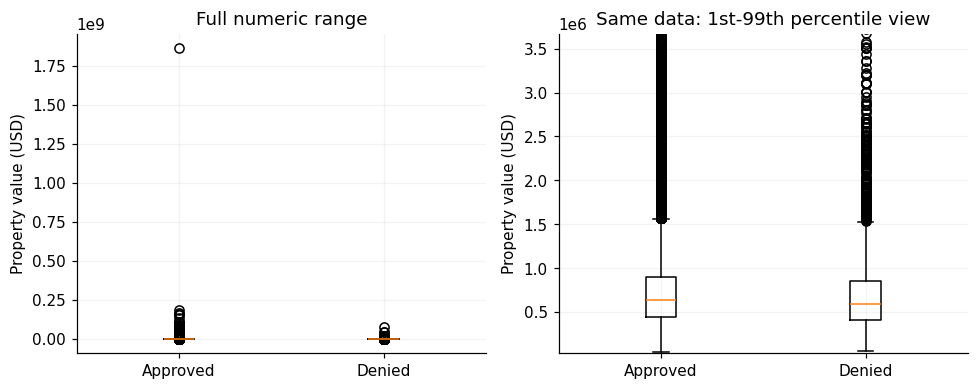

In [ ]:
s = pd.to_numeric(df["property_value"], errors="coerce")
group_summary = s.groupby(decision).describe()
group_summary = group_summary.reindex(["Approved", "Denied"])
display(group_summary)

approved_values = s[(decision == "Approved") & s.notna()]
denied_values = s[(decision == "Denied") & s.notna()]
zoom_low = s.quantile(0.01)
zoom_high = s.quantile(0.99)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax in axes:
    ax.boxplot([approved_values, denied_values], showfliers=True)
    ax.set_xticks([1, 2], ["Approved", "Denied"])
    ax.set_ylabel("Property value (USD)")
axes[0].set_title("Full numeric range")
axes[1].set_title("Same data: 1st-99th percentile view")
axes[1].set_ylim(zoom_low - (zoom_high-zoom_low)*0.05,
                 zoom_high + (zoom_high-zoom_low)*0.05)
plt.tight_layout()
plt.show()

**실제 결과와 해석:** 승인군 부동산가치 중앙값은 635,000 USD, 거절군은 595,000 USD로 40,000 USD 차이다. 평균은 약 877,156 대 777,896 USD이지만 승인군에 특히 큰 극단값이 있다. 중앙 50% 범위는 445,000~895,000 대 405,000~855,000 USD로 상당히 겹친다. 숫자 관측 승인 60,019건·거절 5,390건만 비교한 것이며, 가치 NA 집단의 높은 거절률을 이 표에서 놓치면 안 된다.

### 5-1-4. `loan_term`: 평균·중앙값·상자그림
승인군과 거절군의 중심과 퍼짐을 비교한다. 전체 범위와 세로축 확대를 함께 표시해 극단값과 중심부를 모두 보존한다.

,count,mean,std,min,25%,50%,75%,max
decision,,,,,,,,
Approved,"60,206.000",339.748,66.837,6.000,360.000,360.000,360.000,492.000
Denied,"5,687.000",333.055,70.938,6.000,360.000,360.000,360.000,480.000


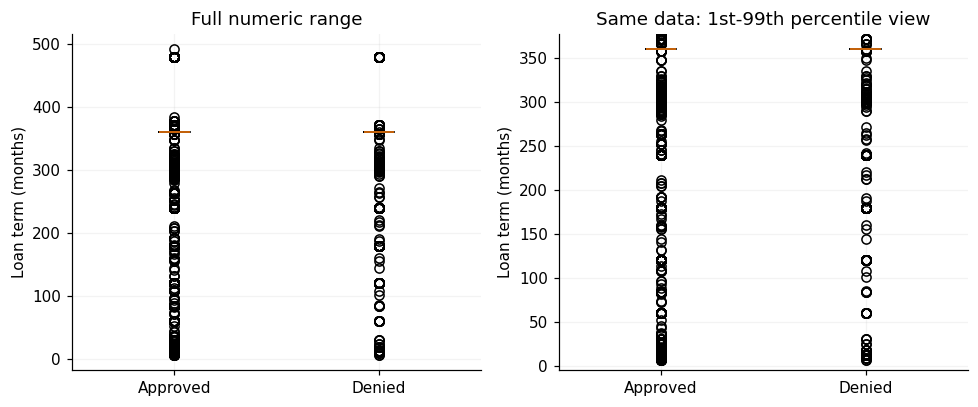

In [ ]:
s = pd.to_numeric(df["loan_term"], errors="coerce")
group_summary = s.groupby(decision).describe()
group_summary = group_summary.reindex(["Approved", "Denied"])
display(group_summary)

approved_values = s[(decision == "Approved") & s.notna()]
denied_values = s[(decision == "Denied") & s.notna()]
zoom_low = s.quantile(0.01)
zoom_high = s.quantile(0.99)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax in axes:
    ax.boxplot([approved_values, denied_values], showfliers=True)
    ax.set_xticks([1, 2], ["Approved", "Denied"])
    ax.set_ylabel("Loan term (months)")
axes[0].set_title("Full numeric range")
axes[1].set_title("Same data: 1st-99th percentile view")
axes[1].set_ylim(zoom_low - (zoom_high-zoom_low)*0.05,
                 zoom_high + (zoom_high-zoom_low)*0.05)
plt.tight_layout()
plt.show()

**실제 결과와 해석:** 승인군·거절군의 중앙값과 25·75백분위가 모두 360개월이다. 평균만 보면 승인 339.75개월·거절 333.05개월로 약 6.69개월 차이지만 이를 일반적인 대출기간 차이로 과장하기 어렵다. 360개월 집중 때문에 상자그림이 선처럼 보이는 것은 오류가 아니다. 기간을 연속형 하나로 쓰기보다 30년/그 외 및 실제 기간 범주의 구성과 상품 맥락을 이후에 검토할 수 있다.

### 5-1-5. `loan_to_value_ratio`: 평균·중앙값·상자그림
승인군과 거절군의 중심과 퍼짐을 비교한다. 전체 범위와 세로축 확대를 함께 표시해 극단값과 중심부를 모두 보존한다.

,count,mean,std,min,25%,50%,75%,max
decision,,,,,,,,
Approved,"59,432.000",77.703,18.651,0.620,70.000,80.000,94.111,220.230
Denied,"5,360.000",78.956,22.027,0.167,70.000,80.000,95.000,342.188


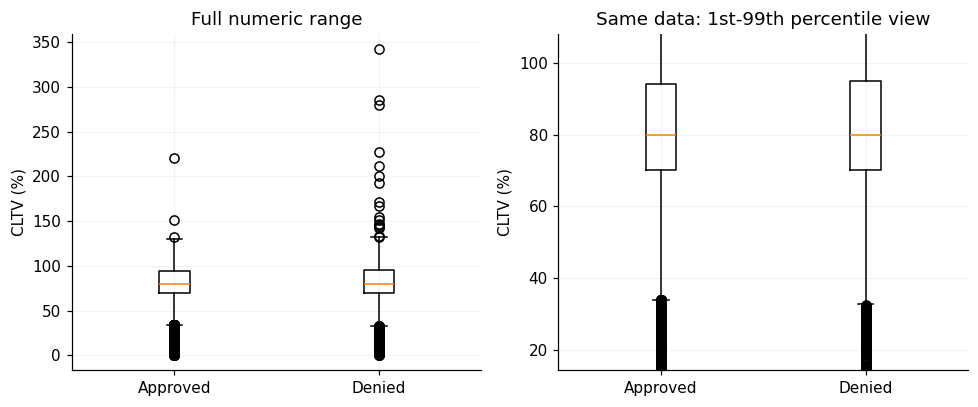

In [ ]:
s = pd.to_numeric(df["loan_to_value_ratio"], errors="coerce")
group_summary = s.groupby(decision).describe()
group_summary = group_summary.reindex(["Approved", "Denied"])
display(group_summary)

approved_values = s[(decision == "Approved") & s.notna()]
denied_values = s[(decision == "Denied") & s.notna()]
zoom_low = s.quantile(0.01)
zoom_high = s.quantile(0.99)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax in axes:
    ax.boxplot([approved_values, denied_values], showfliers=True)
    ax.set_xticks([1, 2], ["Approved", "Denied"])
    ax.set_ylabel("CLTV (%)")
axes[0].set_title("Full numeric range")
axes[1].set_title("Same data: 1st-99th percentile view")
axes[1].set_ylim(zoom_low - (zoom_high-zoom_low)*0.05,
                 zoom_high + (zoom_high-zoom_low)*0.05)
plt.tight_layout()
plt.show()

**실제 결과와 해석:** 승인군·거절군 CLTV 중앙값은 모두 80%이고 25백분위도 모두 70%다. 평균은 승인 77.703%·거절 78.956%로 거절군이 약 1.253%p 높지만 중심 위치의 분리는 작다. 75백분위는 94.111% 대 95%이다. DTI와 달리 CLTV 한 변수의 전체 중앙값 비교만으로는 승인/거절이 잘 나뉜다고 보기 어렵다. 높은 구간의 비선형 관계나 상품별 차이가 없는 것으로 확정한 것도 아니다.

### 5-2. DTI 범주별 거절률
DTI가 커질수록 거절률이 실제로 커지는지 크기 순으로 본다. 평균 DTI를 억지로 계산하지 않는다. NA·Exempt는 순서형 수치 구간에 포함하지 않고 표의 마지막에 두며, 그래프에서는 별도 색으로 표시한다.

decision,신청건수,Approved,Denied,거절률_pct
debt_to_income_ratio,,,,
<20%,2487,2229,258,10.374
20%-<30%,8241,7918,323,3.919
30%-<36%,9480,9107,373,3.935
36,1964,1877,87,4.430
37,2106,2022,84,3.989
38,2189,2107,82,3.746
39,2337,2237,100,4.279
40,2533,2426,107,4.224
41,2579,2458,121,4.692


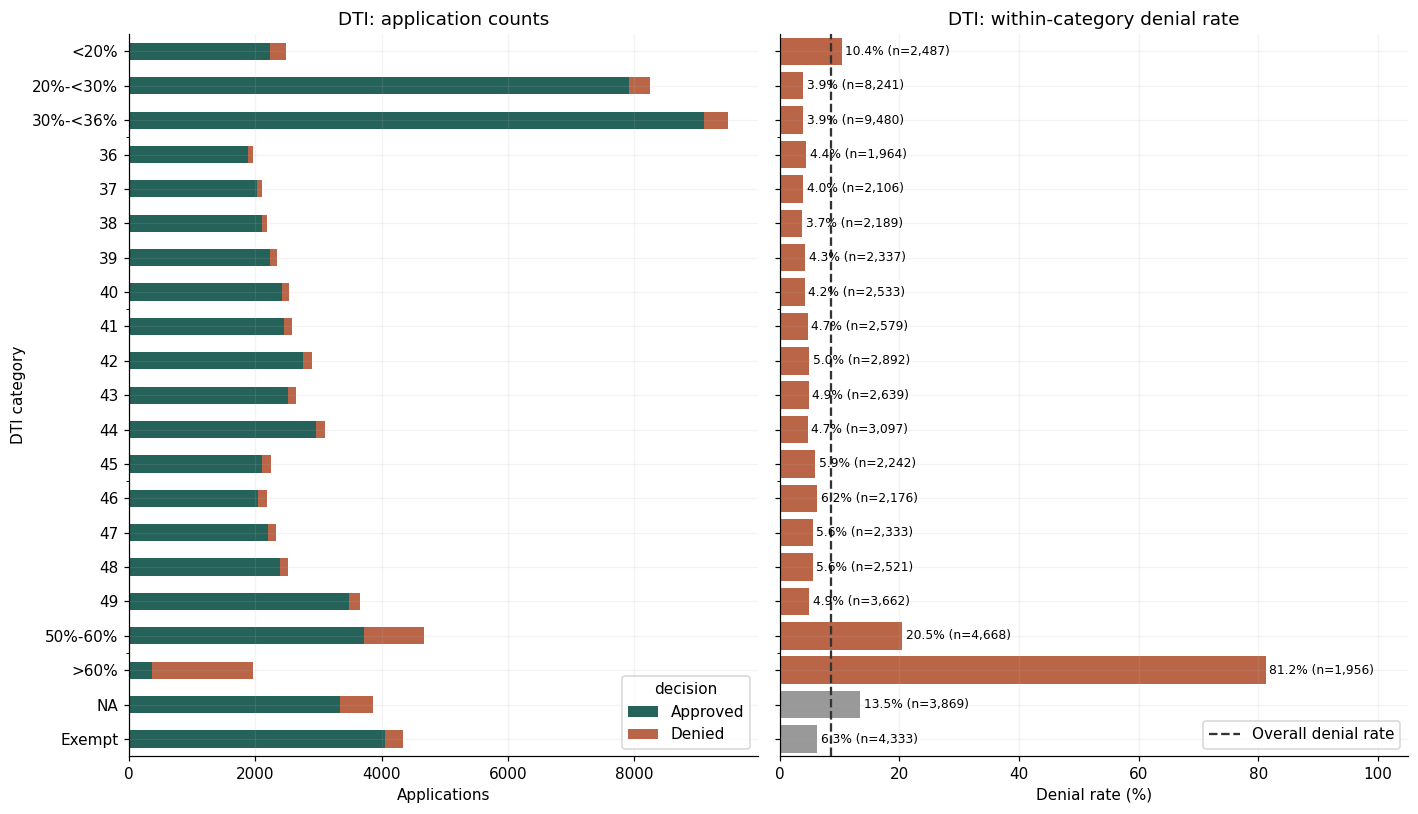

In [ ]:
dti_order = ['<20%', '20%-<30%', '30%-<36%', '36', '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47', '48', '49', '50%-60%', '>60%', 'NA', 'Exempt']
dti_table = pd.crosstab(df_text["debt_to_income_ratio"], decision)
dti_table = dti_table.reindex(index=dti_order, columns=["Approved", "Denied"], fill_value=0)
dti_table["신청건수"] = dti_table["Approved"] + dti_table["Denied"]
dti_table["거절률_pct"] = dti_table["Denied"] / dti_table["신청건수"] * 100
display(dti_table[["신청건수", "Approved", "Denied", "거절률_pct"]])

fig, axes = plt.subplots(1, 2, figsize=(13, 7.5), sharey=True)
dti_table[["Approved", "Denied"]].plot.barh(stacked=True, ax=axes[0],
                                           color=["#256259", "#ba6548"])
colors = ["#ba6548"] * 19 + ["#999999", "#999999"]
axes[1].barh(dti_table.index, dti_table["거절률_pct"], color=colors)
axes[1].axvline(baseline_denial, color="#333333", linestyle="--", label="Overall denial rate")
for y in range(len(dti_table)):
    r = dti_table["거절률_pct"].iloc[y]
    n = dti_table["신청건수"].iloc[y]
    axes[1].text(r + 0.6, y, f"{r:.1f}% (n={n:,})", va="center", fontsize=8)
axes[0].invert_yaxis()
axes[0].set(title="DTI: application counts", xlabel="Applications", ylabel="DTI category")
axes[1].set(title="DTI: within-category denial rate", xlabel="Denial rate (%)", xlim=(0, 105))
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

**실제 결과와 해석:**

| DTI 원문 | 전체 | 승인 | 거절 | 거절률 계산 |
|---|---:|---:|---:|---:|
| <20% | 2,487 | 2,229 | 258 | 258/2,487 = 10.37% |
| 20%-<30% | 8,241 | 7,918 | 323 | 323/8,241 = 3.92% |
| 30%-<36% | 9,480 | 9,107 | 373 | 373/9,480 = 3.93% |
| 49 | 3,662 | 3,481 | 181 | 181/3,662 = 4.94% |
| 50%-60% | 4,668 | 3,712 | 956 | 956/4,668 = 20.48% |
| >60% | 1,956 | 367 | 1,589 | 1,589/1,956 = 81.24% |

**인사이트:** 높은 DTI 구간, 특히 공개 라벨 `50%-60%`와 `>60%`에서 거절률이 크게 높아진다. 하지만 전체 구간에서 매 단계 단조롭게 증가하지는 않는다. `<20%`는 20~36% 구간보다 높고 36~49 사이에서도 오르내린다. 따라서 “DTI가 낮으면 항상 유리하다” 또는 모든 구간에 동일한 선형 효과가 있다고 결론내리지 않는다.

`>60%`는 전체의 2.78%(1,956/70,304)이지만 전체 거절의 **26.42%(1,589/6,015)**를 차지한다. 50%-60%와 >60%를 합하면 전체의 **9.42%(6,624/70,304)**에서 거절의 **42.31%(2,545/6,015)**가 관측된다. 높은 구간이 거절을 설명할 중요한 후보이지만, 모든 거절을 포괄하지는 않는다. `<20%`의 높은 거절률 원인은 현재 단변량 표만으로 확인할 수 없다. 원문 범주를 보존하고 상품·담보순위 구성과 함께 후속 검토할 문제다.

### 5-3. 범주별 승인·거절·거절률
왼쪽 그래프는 승인·거절 건수, 오른쪽은 **해당 범주 안에서의 거절률**이다. 오른쪽 괄호에 전체 신청 수 n을 표시한다. 희귀 기준(100건 미만 또는 0.5% 미만)은 ④와 같으며 해당 범주를 자동 병합하지 않는다. 인구학적 차이는 다른 요인을 통제하지 않은 관측 차이이므로 차별의 증거 또는 인과효과로 확정하지 않는다.

### 5-3-1. `loan_type`와 거절률
범주별 분모와 거절 수를 함께 확인한다.

decision,신청건수,Approved,Denied,거절률_pct,희귀_점검
loan_type,,,,,
1,61414,56383,5031,8.192,False
2,6446,5666,780,12.101,False
3,2175,2000,175,8.046,False
4,269,240,29,10.781,True


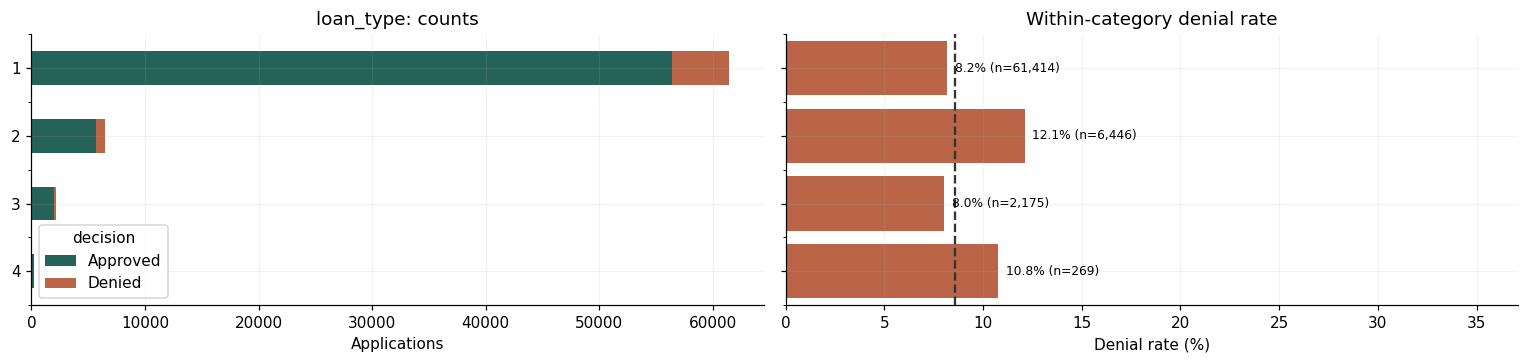

In [ ]:
comparison = pd.crosstab(df_text["loan_type"], decision)
comparison = comparison.reindex(columns=["Approved", "Denied"], fill_value=0)
comparison["신청건수"] = comparison["Approved"] + comparison["Denied"]
comparison["거절률_pct"] = comparison["Denied"] / comparison["신청건수"] * 100
comparison["희귀_점검"] = (comparison["신청건수"] < 100) | (comparison["신청건수"] / len(df) < 0.005)
display(comparison[["신청건수", "Approved", "Denied", "거절률_pct", "희귀_점검"]])

fig, axes = plt.subplots(1, 2, figsize=(14, 3.4), sharey=True)
comparison[["Approved", "Denied"]].plot.barh(stacked=True, ax=axes[0],
                                             color=["#256259", "#ba6548"])
axes[1].barh(comparison.index, comparison["거절률_pct"], color="#ba6548")
axes[1].axvline(baseline_denial, color="#333333", linestyle="--")
for y in range(len(comparison)):
    r = comparison["거절률_pct"].iloc[y]
    n = comparison["신청건수"].iloc[y]
    axes[1].text(r + 0.4, y, f"{r:.1f}% (n={n:,})", va="center", fontsize=8)
axes[0].invert_yaxis()
axes[0].set(title="loan_type: counts", xlabel="Applications", ylabel="")
axes[1].set(title="Within-category denial rate", xlabel="Denial rate (%)")
axes[1].set_xlim(0, max(30, comparison["거절률_pct"].max() + 25))
plt.tight_layout()
plt.show()

**실제 결과와 해석:** Conventional 5,031/61,414 = 8.19%, FHA 780/6,446 = 12.10%, VA 175/2,175 = 8.05%, RHS/FSA 29/269 = 10.78%다. FHA의 관측 거절률이 Conventional보다 약 3.91%p 높다. 이는 신청자 소득·DTI·자격 등 구성이 다른 상품 사이의 단순 비교다. RHS/FSA는 269건으로 작아 큰 표본 상품과 비슷한 확신으로 순위를 매기지 않는다.

### 5-3-2. `lien_status`와 거절률
범주별 분모와 거절 수를 함께 확인한다.

decision,신청건수,Approved,Denied,거절률_pct,희귀_점검
lien_status,,,,,
1,65623,60771,4852,7.394,False
2,4681,3518,1163,24.845,False


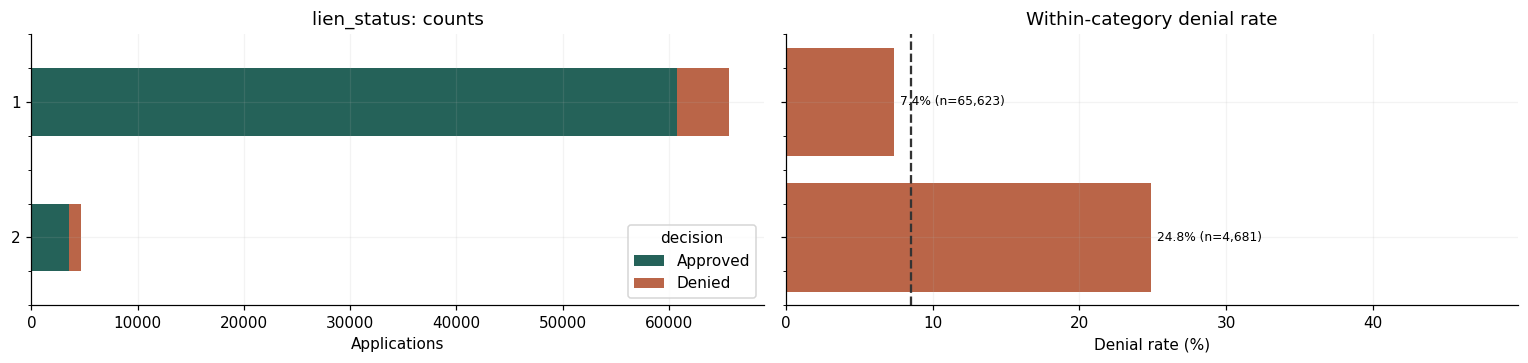

In [ ]:
comparison = pd.crosstab(df_text["lien_status"], decision)
comparison = comparison.reindex(columns=["Approved", "Denied"], fill_value=0)
comparison["신청건수"] = comparison["Approved"] + comparison["Denied"]
comparison["거절률_pct"] = comparison["Denied"] / comparison["신청건수"] * 100
comparison["희귀_점검"] = (comparison["신청건수"] < 100) | (comparison["신청건수"] / len(df) < 0.005)
display(comparison[["신청건수", "Approved", "Denied", "거절률_pct", "희귀_점검"]])

fig, axes = plt.subplots(1, 2, figsize=(14, 3.4), sharey=True)
comparison[["Approved", "Denied"]].plot.barh(stacked=True, ax=axes[0],
                                             color=["#256259", "#ba6548"])
axes[1].barh(comparison.index, comparison["거절률_pct"], color="#ba6548")
axes[1].axvline(baseline_denial, color="#333333", linestyle="--")
for y in range(len(comparison)):
    r = comparison["거절률_pct"].iloc[y]
    n = comparison["신청건수"].iloc[y]
    axes[1].text(r + 0.4, y, f"{r:.1f}% (n={n:,})", va="center", fontsize=8)
axes[0].invert_yaxis()
axes[0].set(title="lien_status: counts", xlabel="Applications", ylabel="")
axes[1].set(title="Within-category denial rate", xlabel="Denial rate (%)")
axes[1].set_xlim(0, max(30, comparison["거절률_pct"].max() + 25))
plt.tight_layout()
plt.show()

**실제 결과와 해석:** 선순위는 4,852/65,623 = 7.39%, 후순위는 1,163/4,681 = 24.85%다. 차이는 17.45%p이고 거절률 비는 약 3.36배다. 4,681건의 후순위 기록에서 뚜렷한 차이가 보이므로 이후 중요한 설명 후보다. 다만 후순위 자체의 인과효과는 아니며, 함께 발생하는 DTI·대출상품 차이를 검토해야 한다.

### 5-3-3. `occupancy_type`와 거절률
범주별 분모와 거절 수를 함께 확인한다.

decision,신청건수,Approved,Denied,거절률_pct,희귀_점검
occupancy_type,,,,,
1,60255,55303,4952,8.218,False
2,2144,1990,154,7.183,False
3,7905,6996,909,11.499,False


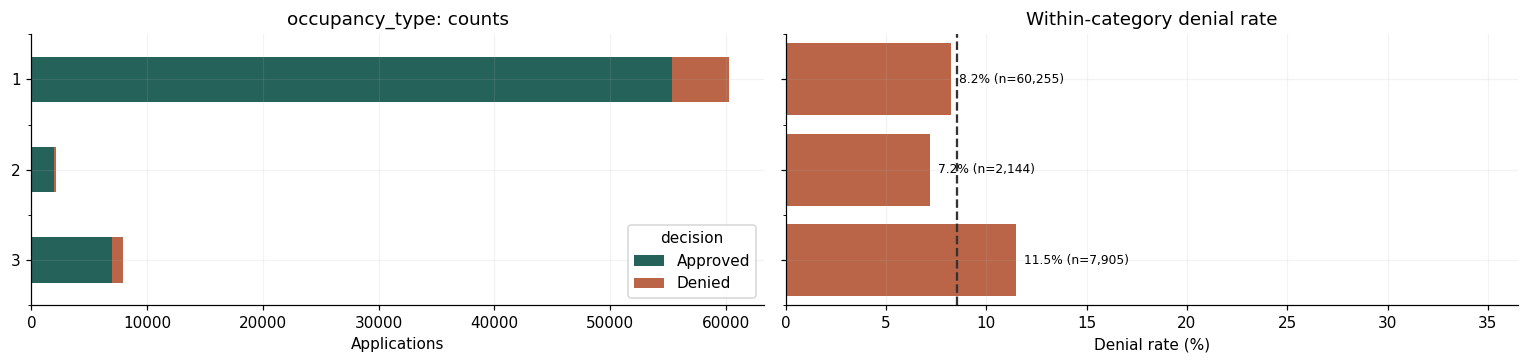

In [ ]:
comparison = pd.crosstab(df_text["occupancy_type"], decision)
comparison = comparison.reindex(columns=["Approved", "Denied"], fill_value=0)
comparison["신청건수"] = comparison["Approved"] + comparison["Denied"]
comparison["거절률_pct"] = comparison["Denied"] / comparison["신청건수"] * 100
comparison["희귀_점검"] = (comparison["신청건수"] < 100) | (comparison["신청건수"] / len(df) < 0.005)
display(comparison[["신청건수", "Approved", "Denied", "거절률_pct", "희귀_점검"]])

fig, axes = plt.subplots(1, 2, figsize=(14, 3.4), sharey=True)
comparison[["Approved", "Denied"]].plot.barh(stacked=True, ax=axes[0],
                                             color=["#256259", "#ba6548"])
axes[1].barh(comparison.index, comparison["거절률_pct"], color="#ba6548")
axes[1].axvline(baseline_denial, color="#333333", linestyle="--")
for y in range(len(comparison)):
    r = comparison["거절률_pct"].iloc[y]
    n = comparison["신청건수"].iloc[y]
    axes[1].text(r + 0.4, y, f"{r:.1f}% (n={n:,})", va="center", fontsize=8)
axes[0].invert_yaxis()
axes[0].set(title="occupancy_type: counts", xlabel="Applications", ylabel="")
axes[1].set(title="Within-category denial rate", xlabel="Denial rate (%)")
axes[1].set_xlim(0, max(30, comparison["거절률_pct"].max() + 25))
plt.tight_layout()
plt.show()

**실제 결과와 해석:** 주거주 4,952/60,255 = 8.22%, 제2주택 154/2,144 = 7.18%, 투자용 909/7,905 = 11.50%다. 투자용이 상대적으로 높지만 제2주택이 주거주보다 높지는 않다. 이용목적만으로 단순한 위험 순서를 정하기 어렵고, 소득과 담보·대출 규모 구성의 차이도 확인해야 한다.

### 5-3-4. `applicant_age`와 거절률
범주별 분모와 거절 수를 함께 확인한다.

decision,신청건수,Approved,Denied,거절률_pct,희귀_점검
applicant_age,,,,,
<25,1921,1749,172,8.954,False
25-34,21289,20002,1287,6.045,False
35-44,20376,18722,1654,8.117,False
45-54,11276,10128,1148,10.181,False
55-64,7841,6955,886,11.300,False
65-74,3677,3188,489,13.299,False
>74,955,816,139,14.555,False
8888,2969,2729,240,8.084,False


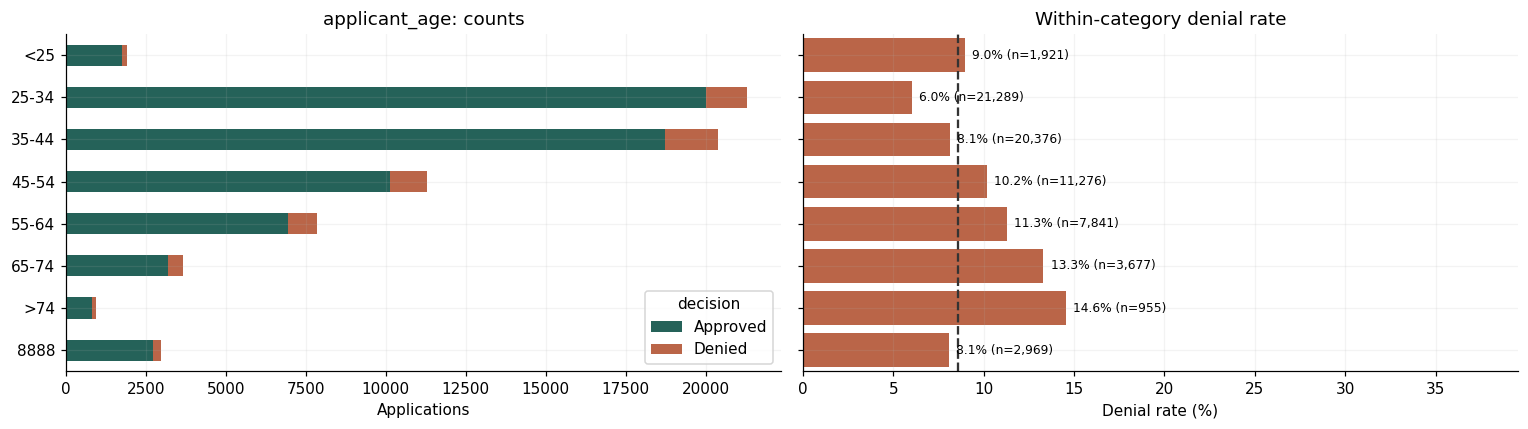

In [ ]:
comparison = pd.crosstab(df_text["applicant_age"], decision)
comparison = comparison.reindex(columns=["Approved", "Denied"], fill_value=0)
comparison = comparison.reindex(['<25', '25-34', '35-44', '45-54', '55-64', '65-74', '>74', '8888'])
comparison["신청건수"] = comparison["Approved"] + comparison["Denied"]
comparison["거절률_pct"] = comparison["Denied"] / comparison["신청건수"] * 100
comparison["희귀_점검"] = (comparison["신청건수"] < 100) | (comparison["신청건수"] / len(df) < 0.005)
display(comparison[["신청건수", "Approved", "Denied", "거절률_pct", "희귀_점검"]])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.0), sharey=True)
comparison[["Approved", "Denied"]].plot.barh(stacked=True, ax=axes[0],
                                             color=["#256259", "#ba6548"])
axes[1].barh(comparison.index, comparison["거절률_pct"], color="#ba6548")
axes[1].axvline(baseline_denial, color="#333333", linestyle="--")
for y in range(len(comparison)):
    r = comparison["거절률_pct"].iloc[y]
    n = comparison["신청건수"].iloc[y]
    axes[1].text(r + 0.4, y, f"{r:.1f}% (n={n:,})", va="center", fontsize=8)
axes[0].invert_yaxis()
axes[0].set(title="applicant_age: counts", xlabel="Applications", ylabel="")
axes[1].set(title="Within-category denial rate", xlabel="Denial rate (%)")
axes[1].set_xlim(0, max(30, comparison["거절률_pct"].max() + 25))
plt.tight_layout()
plt.show()

**실제 결과와 해석:** 25~34세는 1,287/21,289 = 6.05%, 35~44세 8.12%, 45~54세 10.18%, 55~64세 11.30%, 65~74세 13.30%, >74는 139/955 = 14.55%다. 25세 미만은 8.95%로 25~34세보다 높다. 모든 나이에서 단조로운 증가가 아니며, 연령 때문에 거절되었다고 볼 수 없다. 소득·대출기간·상품 차이가 함께 있을 수 있다. 8888은 8.08%로 별도 코드 집단이다.

### 5-3-5. `derived_sex`와 거절률
범주별 분모와 거절 수를 함께 확인한다.

decision,신청건수,Approved,Denied,거절률_pct,희귀_점검
derived_sex,,,,,
Female,14559,13120,1439,9.884,False
Joint,29176,27371,1805,6.187,False
Male,20402,18216,2186,10.715,False
Sex Not Available,6167,5582,585,9.486,False


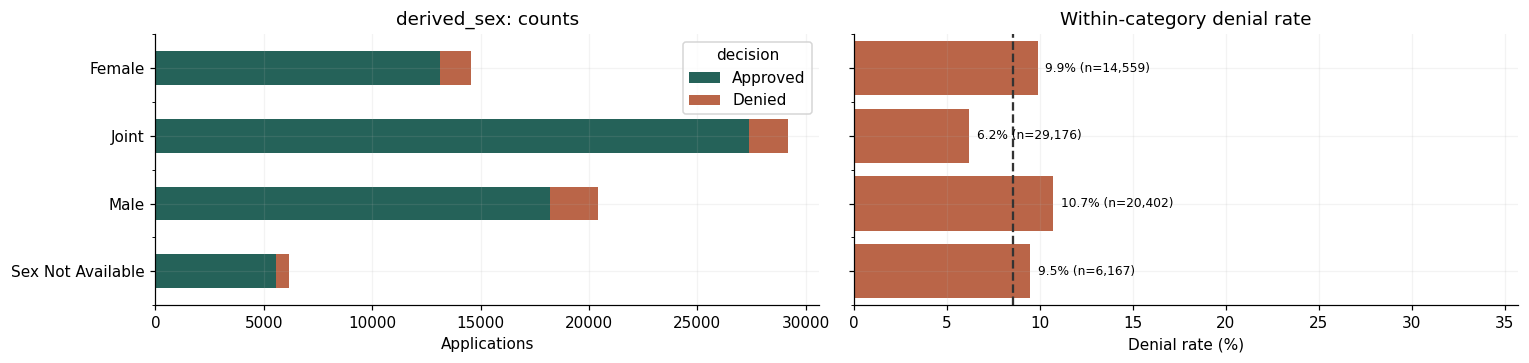

In [ ]:
comparison = pd.crosstab(df_text["derived_sex"], decision)
comparison = comparison.reindex(columns=["Approved", "Denied"], fill_value=0)
comparison["신청건수"] = comparison["Approved"] + comparison["Denied"]
comparison["거절률_pct"] = comparison["Denied"] / comparison["신청건수"] * 100
comparison["희귀_점검"] = (comparison["신청건수"] < 100) | (comparison["신청건수"] / len(df) < 0.005)
display(comparison[["신청건수", "Approved", "Denied", "거절률_pct", "희귀_점검"]])

fig, axes = plt.subplots(1, 2, figsize=(14, 3.4), sharey=True)
comparison[["Approved", "Denied"]].plot.barh(stacked=True, ax=axes[0],
                                             color=["#256259", "#ba6548"])
axes[1].barh(comparison.index, comparison["거절률_pct"], color="#ba6548")
axes[1].axvline(baseline_denial, color="#333333", linestyle="--")
for y in range(len(comparison)):
    r = comparison["거절률_pct"].iloc[y]
    n = comparison["신청건수"].iloc[y]
    axes[1].text(r + 0.4, y, f"{r:.1f}% (n={n:,})", va="center", fontsize=8)
axes[0].invert_yaxis()
axes[0].set(title="derived_sex: counts", xlabel="Applications", ylabel="")
axes[1].set(title="Within-category denial rate", xlabel="Denial rate (%)")
axes[1].set_xlim(0, max(30, comparison["거절률_pct"].max() + 25))
plt.tight_layout()
plt.show()

**실제 결과와 해석:** Joint는 1,805/29,176 = 6.19%, Female은 1,439/14,559 = 9.88%, Male은 2,186/20,402 = 10.71%다. Joint의 관측 거절률이 더 낮다. derived_sex가 신청자·공동신청자를 함께 반영하므로 이를 “개인의 성별 효과”라고 해석하지 않는다. 공동신청 여부·소득·자산 등의 차이를 분리한 분석은 아직 하지 않았다.

### 5-3-6. `derived_race`와 거절률
범주별 분모와 거절 수를 함께 확인한다.

decision,신청건수,Approved,Denied,거절률_pct,희귀_점검
derived_race,,,,,
2 or more minority races,150,126,24,16.000,True
American Indian or Alaska Native,208,171,37,17.788,True
Asian,6972,6302,670,9.610,False
Black or African American,4786,4004,782,16.339,False
Free Form Text Only,14,4,10,71.429,True
Joint,2101,1977,124,5.902,False
Native Hawaiian or Other Pacific Islander,74,57,17,22.973,True
Race Not Available,12424,11186,1238,9.965,False
White,43575,40462,3113,7.144,False


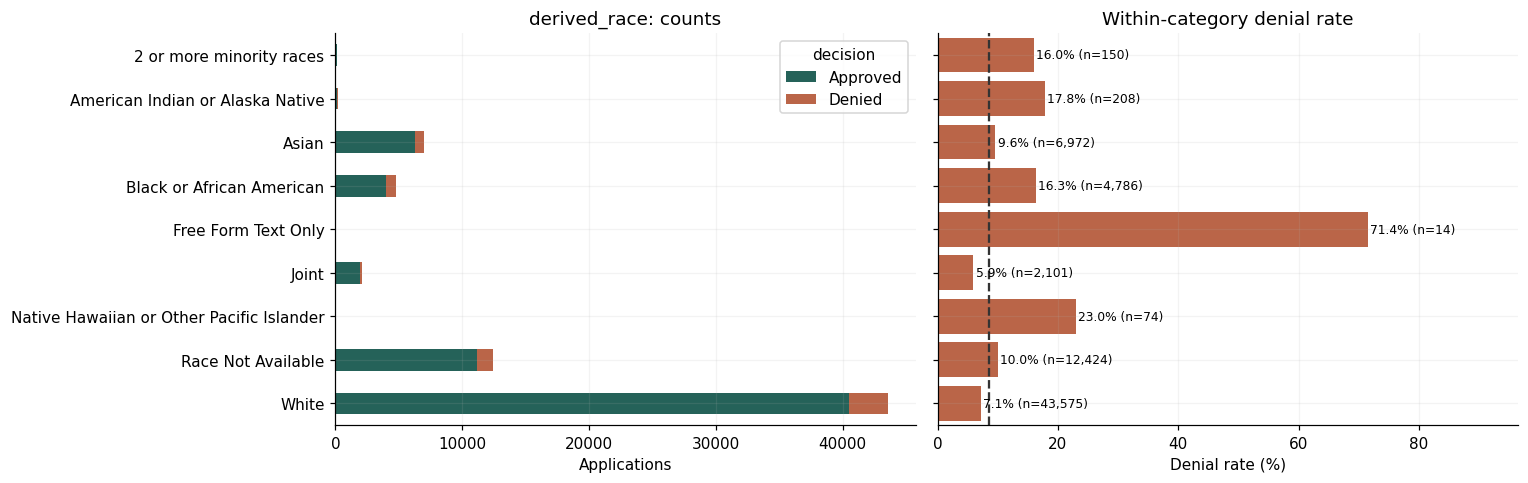

In [ ]:
comparison = pd.crosstab(df_text["derived_race"], decision)
comparison = comparison.reindex(columns=["Approved", "Denied"], fill_value=0)
comparison["신청건수"] = comparison["Approved"] + comparison["Denied"]
comparison["거절률_pct"] = comparison["Denied"] / comparison["신청건수"] * 100
comparison["희귀_점검"] = (comparison["신청건수"] < 100) | (comparison["신청건수"] / len(df) < 0.005)
display(comparison[["신청건수", "Approved", "Denied", "거절률_pct", "희귀_점검"]])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
comparison[["Approved", "Denied"]].plot.barh(stacked=True, ax=axes[0],
                                             color=["#256259", "#ba6548"])
axes[1].barh(comparison.index, comparison["거절률_pct"], color="#ba6548")
axes[1].axvline(baseline_denial, color="#333333", linestyle="--")
for y in range(len(comparison)):
    r = comparison["거절률_pct"].iloc[y]
    n = comparison["신청건수"].iloc[y]
    axes[1].text(r + 0.4, y, f"{r:.1f}% (n={n:,})", va="center", fontsize=8)
axes[0].invert_yaxis()
axes[0].set(title="derived_race: counts", xlabel="Applications", ylabel="")
axes[1].set(title="Within-category denial rate", xlabel="Denial rate (%)")
axes[1].set_xlim(0, max(30, comparison["거절률_pct"].max() + 25))
plt.tight_layout()
plt.show()

**실제 결과와 해석:** White는 3,113/43,575 = 7.14%, Asian 670/6,972 = 9.61%, Black or African American 782/4,786 = 16.34%다. 관측된 격차는 후속 설명이 필요한 결과이지만 심사요인을 통제하지 않았으므로 원인이나 차별로 단정할 수 없다. Free Form Text Only는 10/14 = 71.43%로 가장 높아도 14건뿐이다. Native Hawaiian or Other Pacific Islander도 17/74 = 22.97%로 작은 분모를 함께 봐야 한다.

### 5-3-7. `derived_ethnicity`와 거절률
범주별 분모와 거절 수를 함께 확인한다.

decision,신청건수,Approved,Denied,거절률_pct,희귀_점검
derived_ethnicity,,,,,
Ethnicity Not Available,11262,10169,1093,9.705,False
Free Form Text Only,30,16,14,46.667,True
Hispanic or Latino,7053,6055,998,14.150,False
Joint,1790,1675,115,6.425,False
Not Hispanic or Latino,50169,46374,3795,7.564,False


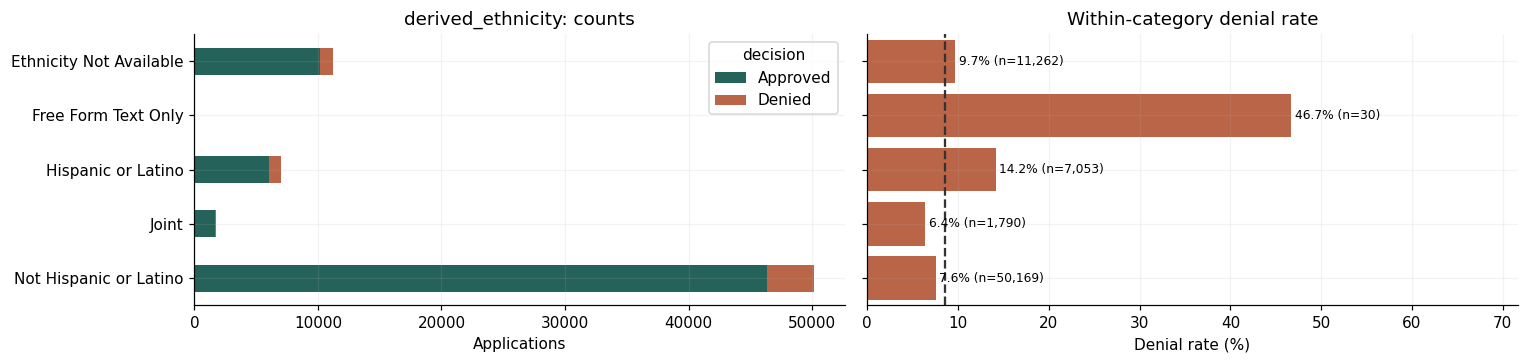

In [ ]:
comparison = pd.crosstab(df_text["derived_ethnicity"], decision)
comparison = comparison.reindex(columns=["Approved", "Denied"], fill_value=0)
comparison["신청건수"] = comparison["Approved"] + comparison["Denied"]
comparison["거절률_pct"] = comparison["Denied"] / comparison["신청건수"] * 100
comparison["희귀_점검"] = (comparison["신청건수"] < 100) | (comparison["신청건수"] / len(df) < 0.005)
display(comparison[["신청건수", "Approved", "Denied", "거절률_pct", "희귀_점검"]])

fig, axes = plt.subplots(1, 2, figsize=(14, 3.4), sharey=True)
comparison[["Approved", "Denied"]].plot.barh(stacked=True, ax=axes[0],
                                             color=["#256259", "#ba6548"])
axes[1].barh(comparison.index, comparison["거절률_pct"], color="#ba6548")
axes[1].axvline(baseline_denial, color="#333333", linestyle="--")
for y in range(len(comparison)):
    r = comparison["거절률_pct"].iloc[y]
    n = comparison["신청건수"].iloc[y]
    axes[1].text(r + 0.4, y, f"{r:.1f}% (n={n:,})", va="center", fontsize=8)
axes[0].invert_yaxis()
axes[0].set(title="derived_ethnicity: counts", xlabel="Applications", ylabel="")
axes[1].set(title="Within-category denial rate", xlabel="Denial rate (%)")
axes[1].set_xlim(0, max(30, comparison["거절률_pct"].max() + 25))
plt.tight_layout()
plt.show()

**실제 결과와 해석:** Hispanic or Latino는 998/7,053 = 14.15%, Not Hispanic or Latino는 3,795/50,169 = 7.56%로 약 6.59%p 차이다. Joint는 115/1,790 = 6.42%다. Free Form Text Only는 14/30 = 46.67%지만 30건이며 대표적인 집단 차이라고 일반화하지 않는다. ethnicity 차이 자체의 효과를 확인하려면 DTI·소득·상품·지역 등을 함께 검토해야 한다.

### 5-3-8. `preapproval`와 거절률
기존 범주형 비교와 같은 방법으로 신청·승인·거절 건수와 범주 내 거절률을 확인한다. 사전승인 요청과 결과 코드의 보고 규칙도 함께 읽는다.

decision,신청건수,Approved,Denied,거절률_pct,희귀_점검
preapproval,,,,,
1,3609,3609,0,0.000,False
2,66695,60680,6015,9.019,False


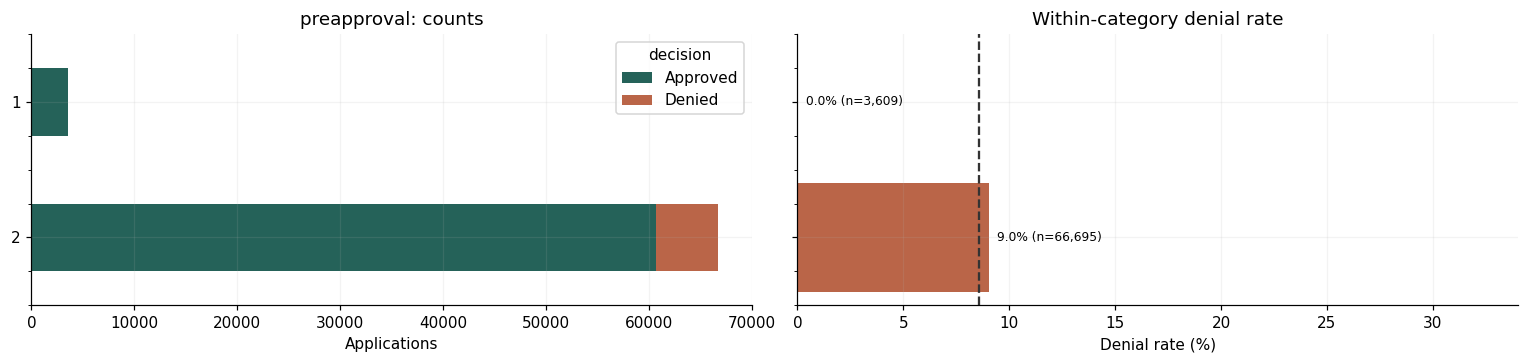

원본 action_taken별 건수


action_taken,1,2,3
preapproval,,,
1,3530,79,0
2,59270,1410,6015


In [ ]:
comparison = pd.crosstab(df_text["preapproval"], decision)
comparison = comparison.reindex(columns=["Approved", "Denied"], fill_value=0)
comparison = comparison.reindex(['1', '2'])
comparison["신청건수"] = comparison["Approved"] + comparison["Denied"]
comparison["거절률_pct"] = comparison["Denied"] / comparison["신청건수"] * 100
comparison["희귀_점검"] = (comparison["신청건수"] < 100) | (comparison["신청건수"] / len(df) < 0.005)
display(comparison[["신청건수", "Approved", "Denied", "거절률_pct", "희귀_점검"]])

fig, axes = plt.subplots(1, 2, figsize=(14, 3.4), sharey=True)
comparison[["Approved", "Denied"]].plot.barh(stacked=True, ax=axes[0],
                                             color=["#256259", "#ba6548"])
axes[1].barh(comparison.index, comparison["거절률_pct"], color="#ba6548")
axes[1].axvline(baseline_denial, color="#333333", linestyle="--")
for y in range(len(comparison)):
    r = comparison["거절률_pct"].iloc[y]
    n = comparison["신청건수"].iloc[y]
    axes[1].text(r + 0.4, y, f"{r:.1f}% (n={n:,})", va="center", fontsize=8)
axes[0].invert_yaxis()
axes[0].set(title="preapproval: counts", xlabel="Applications", ylabel="")
axes[1].set(title="Within-category denial rate", xlabel="Denial rate (%)")
axes[1].set_xlim(0, max(30, comparison["거절률_pct"].max() + 25))
plt.tight_layout()
plt.show()

print("원본 action_taken별 건수")
display(pd.crosstab(df["preapproval"], df["action_taken"]))

**실제 결과와 해석:** 요청(1)은 실행 3,530건 + 승인 후 미수락 79건 = **3,609건**, 거절은 **0/3,609 = 0%**다. 미요청(2)은 승인 60,680건·거절 6,015건으로 **6,015/66,695 × 100 = 9.02%**다.

**보고 구조가 만드는 차이:** [2025 FIG V613](https://ffiec.cfpb.gov/documentation/fig/2025/overview)은 `action_taken=3`이면 `preapproval=2`, `preapproval=1`이면 Action 1·2·7·8로 보고하도록 한다. 사전승인 거절은 Action 7로 구분되며 현재 파일에는 7·8이 없다. 따라서 유효한 보고에서 현재 필터(1·2·3)를 적용하면 요청 집단에는 1·2만 남는다. 요청 집단 거절률 0%를 “요청했기 때문에 심사에 유리하다”는 효과로 해석할 수 없다.

이번 EDA에는 그대로 포함한다. 후속 Action 3 예측에 바로 사용하면 보고 규칙을 학습하는 문제가 생길 수 있고, 로짓 모형에서는 한 범주에 거절이 없는 분리 문제도 검토해야 한다. 실제 사전승인 요청의 효과나 전체 요청 중 거절률은 이 필터 파일만으로 확인할 수 없다.

### 5-3-9. `total_units`와 거절률
기존 범주형 비교와 같은 방법으로 신청·승인·거절 건수와 범주 내 거절률을 확인한다. 숫자와 구간을 원문 범주로 유지하고 소표본을 함께 확인한다.

decision,신청건수,Approved,Denied,거절률_pct,희귀_점검
total_units,,,,,
1,61836,56982,4854,7.850,False
2,4944,4313,631,12.763,False
3,2192,1811,381,17.381,False
4,552,464,88,15.942,False
5-24,648,592,56,8.642,False
25-49,58,56,2,3.448,True
50-99,44,42,2,4.545,True
100-149,9,8,1,11.111,True
>149,21,21,0,0.000,True


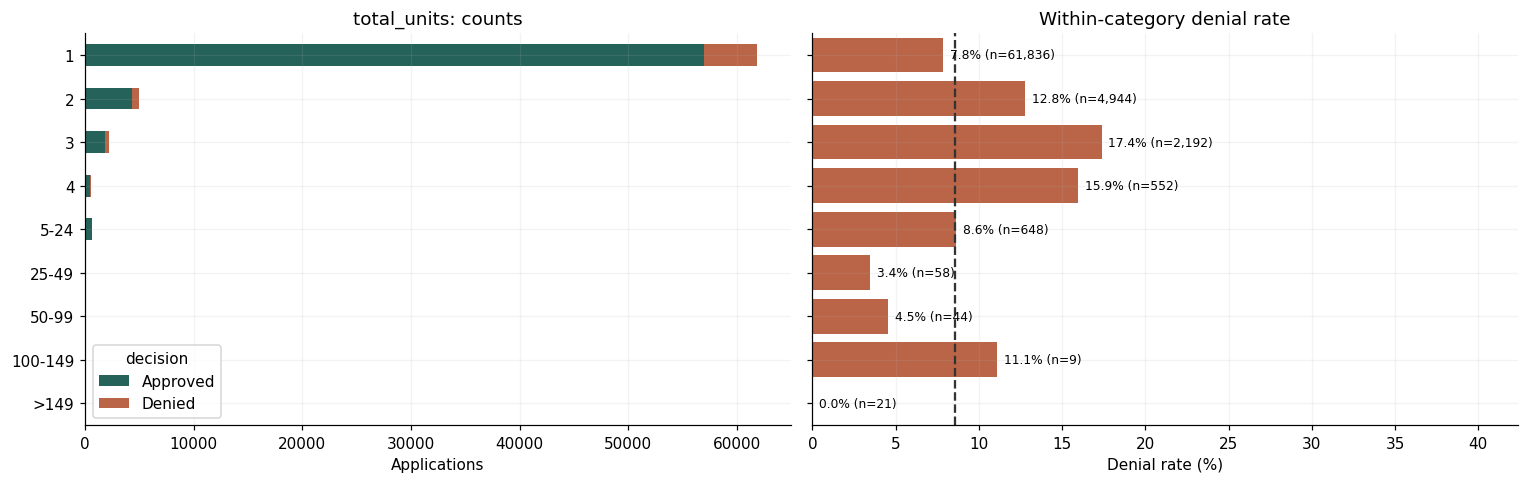

In [ ]:
comparison = pd.crosstab(df_text["total_units"], decision)
comparison = comparison.reindex(columns=["Approved", "Denied"], fill_value=0)
comparison = comparison.reindex(['1', '2', '3', '4', '5-24', '25-49', '50-99', '100-149', '>149'])
comparison["신청건수"] = comparison["Approved"] + comparison["Denied"]
comparison["거절률_pct"] = comparison["Denied"] / comparison["신청건수"] * 100
comparison["희귀_점검"] = (comparison["신청건수"] < 100) | (comparison["신청건수"] / len(df) < 0.005)
display(comparison[["신청건수", "Approved", "Denied", "거절률_pct", "희귀_점검"]])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
comparison[["Approved", "Denied"]].plot.barh(stacked=True, ax=axes[0],
                                             color=["#256259", "#ba6548"])
axes[1].barh(comparison.index, comparison["거절률_pct"], color="#ba6548")
axes[1].axvline(baseline_denial, color="#333333", linestyle="--")
for y in range(len(comparison)):
    r = comparison["거절률_pct"].iloc[y]
    n = comparison["신청건수"].iloc[y]
    axes[1].text(r + 0.4, y, f"{r:.1f}% (n={n:,})", va="center", fontsize=8)
axes[0].invert_yaxis()
axes[0].set(title="total_units: counts", xlabel="Applications", ylabel="")
axes[1].set(title="Within-category denial rate", xlabel="Denial rate (%)")
axes[1].set_xlim(0, max(30, comparison["거절률_pct"].max() + 25))
plt.tight_layout()
plt.show()

**실제 결과와 해석:** 1세대는 **4,854/61,836 = 7.85%**, 2세대 **631/4,944 = 12.76%**, 3세대 **381/2,192 = 17.38%**, 4세대 **88/552 = 15.94%**다. 2~4세대는 1세대보다 높은 관측 거절률을 보이지만 세대수가 커질 때 매 구간 단조롭게 증가하지는 않는다. 이용목적·소득·상품 차이를 통제한 결과도 아니다.

5-24는 56/648 = 8.64%, 25-49는 2/58 = 3.45%, 50-99는 2/44 = 4.55%, 100-149는 1/9 = 11.11%, >149는 0/21 = 0%다. 특히 25세대 이상 구간의 분모는 9~58건으로 매우 작다. >149의 0%를 대규모 담보는 안전하다는 근거로 해석하지 않는다. 구간별로 서로 다른 거래 구성도 가능하므로 이후 분석 범위를 정할 때 활용하되 이번에는 합치거나 제외하지 않는다.

## ⑥ 지역별 EDA — County
County는 ⑤의 범주별 비교와 같은 계산으로 집계하되 공식 명칭을 붙여 한 번만 분석한다. 이름은 [U.S. Census Bureau, 2025 Massachusetts County 표](https://tigerweb.geo.census.gov/tigerwebmain/Files/acs25/tigerweb_acs25_county_ma.html)의 GEOID–BASENAME을 사용했다. NA는 별도 미기재 집단이며 임의의 County로 대치하지 않는다. 분모 500건 미만을 추가로 표시해 작은 지역의 불안정성을 확인한다. 이 기준도 탐색용이다.

decision,County,신청건수,Approved,Denied,거절률_pct,소표본_500미만
county_code,,,,,,
25017,Middlesex,15007,13926,1081,7.203,False
25027,Worcester,9945,9122,823,8.276,False
25009,Essex,7728,7040,688,8.903,False
25021,Norfolk,7039,6516,523,7.430,False
25025,Suffolk,6248,5575,673,10.771,False
25023,Plymouth,6015,5470,545,9.061,False
25005,Bristol,5547,5047,500,9.014,False
25013,Hampden,5181,4698,483,9.323,False
25001,Barnstable,3339,3045,294,8.805,False


미매칭 코드: []


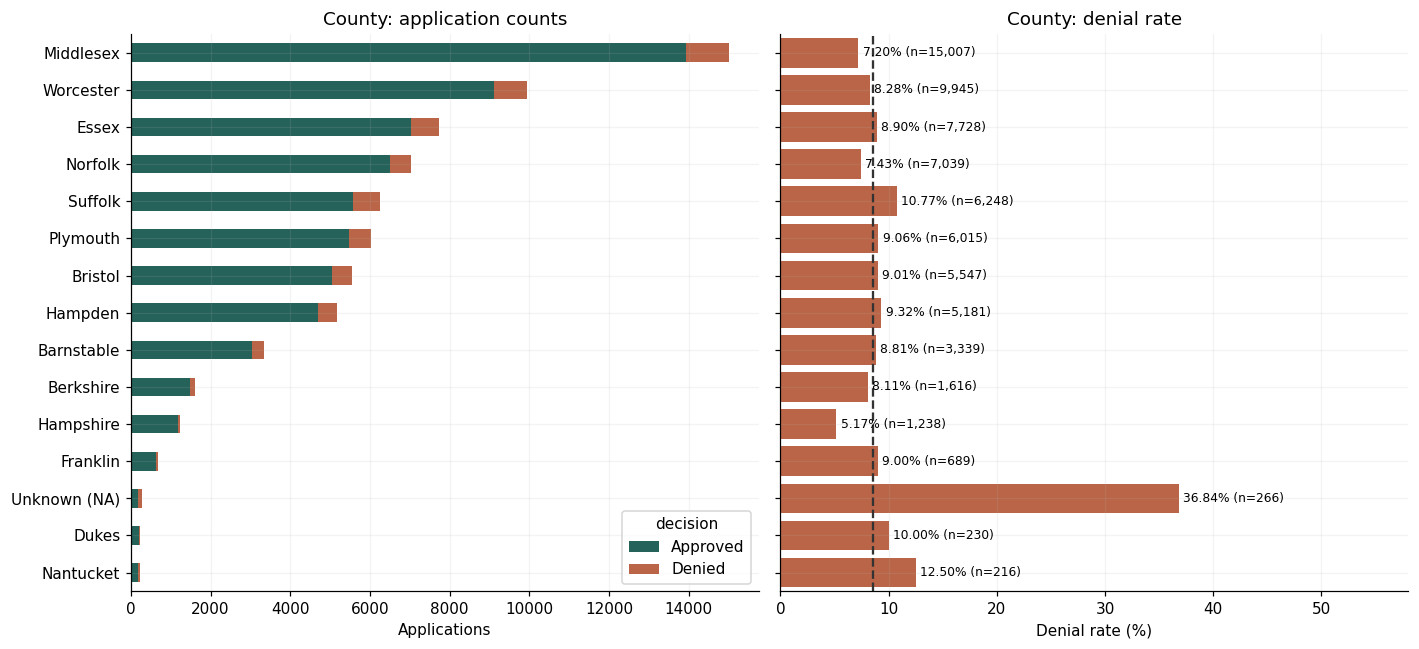

In [ ]:
county_names = {'25001': 'Barnstable', '25003': 'Berkshire', '25005': 'Bristol', '25007': 'Dukes', '25009': 'Essex', '25011': 'Franklin', '25013': 'Hampden', '25015': 'Hampshire', '25017': 'Middlesex', '25019': 'Nantucket', '25021': 'Norfolk', '25023': 'Plymouth', '25025': 'Suffolk', '25027': 'Worcester'}
county_table = pd.crosstab(df_text["county_code"], decision)
county_table = county_table.reindex(columns=["Approved", "Denied"], fill_value=0)
county_table["신청건수"] = county_table["Approved"] + county_table["Denied"]
county_table["거절률_pct"] = county_table["Denied"] / county_table["신청건수"] * 100
county_table["County"] = county_table.index.to_series().map(county_names)
# 표·그림 표시용 라벨만 지정한다. df나 df_text 값은 그대로다.
county_table.loc["NA", "County"] = "Unknown (NA)"
county_table["소표본_500미만"] = county_table["신청건수"] < 500
county_table = county_table.sort_values("신청건수", ascending=False)
display(county_table[["County", "신청건수", "Approved", "Denied", "거절률_pct", "소표본_500미만"]])
print("미매칭 코드:", county_table.index[county_table["County"].isna()].tolist())

fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
county_plot = county_table.set_index("County")
county_plot[["Approved", "Denied"]].plot.barh(stacked=True, ax=axes[0],
                                             color=["#256259", "#ba6548"])
axes[1].barh(county_plot.index, county_plot["거절률_pct"], color="#ba6548")
axes[1].axvline(baseline_denial, color="#333333", linestyle="--")
for y in range(len(county_plot)):
    r = county_plot["거절률_pct"].iloc[y]
    n = county_plot["신청건수"].iloc[y]
    axes[1].text(r + 0.4, y, f"{r:.2f}% (n={n:,})", va="center", fontsize=8)
axes[0].invert_yaxis()
axes[0].set(title="County: application counts", xlabel="Applications", ylabel="")
axes[1].set(title="County: denial rate", xlabel="Denial rate (%)", xlim=(0, 58))
plt.tight_layout()
plt.show()

**실제 결과와 해석:** 신청이 가장 많은 Middlesex는 **1,081/15,007 = 7.20%**, Worcester는 **823/9,945 = 8.28%**다. 1,000건 이상 지역 중 Hampshire는 **64/1,238 = 5.17%**, Suffolk는 **673/6,248 = 10.77%**로 차이가 있다. 이것만으로 지역 자체가 거절의 원인이라고 판단하지 않는다. 상품·주택가치·소득 등 지역별 구성 차이를 아직 통제하지 않았다.

Nantucket는 **27/216 = 12.50%**로 실제 County 중 가장 높지만 216건으로 작다. Dukes도 23/230 = 10.00%이다. 각각 거절 1건이 추가/전환될 때 비율은 약 0.46%p(100/216), 0.43%p(100/230) 변하므로 큰 지역과 똑같이 순위 해석하지 않는다. County NA 집단은 **98/266 = 36.84%**이며 특정 지리적 지역이 아니다. 공식 명칭에 매칭되지 않은 실제 코드가 없음을 출력에서 확인했다.

## ⑦ 변수 간 관계
### 7-1. Pearson·Spearman 상관과 각 쌍의 관측 수
Pearson은 선형 관계, Spearman은 순위에 기반한 단조 관계를 본다. 극단값과 치우침이 큰 데이터이므로 두 결과를 함께 비교한다. 두 변수 모두 숫자로 관측된 행을 **해당 상관 계산에만** 사용한다. 전체 행의 완전사례 삭제는 하지 않는다. 상관쌍마다 분모가 다를 수 있다.

Pearson


,income,loan_amount,property_value,loan_term,loan_to_value_ratio
income,1.000,0.538,0.470,0.017,-0.077
loan_amount,0.538,1.000,0.365,-0.080,-0.016
property_value,0.470,0.365,1.000,-0.047,-0.047
loan_term,0.017,-0.080,-0.047,1.000,0.150
loan_to_value_ratio,-0.077,-0.016,-0.047,0.150,1.000


Spearman


,income,loan_amount,property_value,loan_term,loan_to_value_ratio
income,1.000,0.650,0.705,0.061,-0.217
loan_amount,0.650,1.000,0.798,0.215,0.002
property_value,0.705,0.798,1.000,0.009,-0.415
loan_term,0.061,0.215,0.009,1.000,0.137
loan_to_value_ratio,-0.217,0.002,-0.415,0.137,1.000


각 쌍의 관측 수


,income,loan_amount,property_value,loan_term,loan_to_value_ratio
income,65878,65878,62181,62421,61627
loan_amount,65878,70304,65409,65893,64792
property_value,62181,65409,65409,65358,64673
loan_term,62421,65893,65358,65893,64745
loan_to_value_ratio,61627,64792,64673,64745,64792


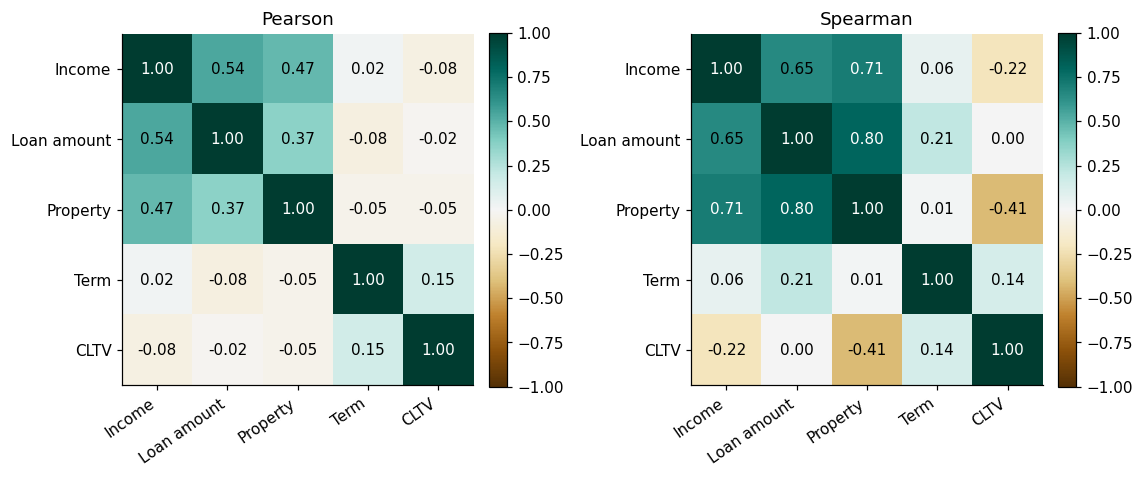

In [ ]:
pearson = numeric.corr(method="pearson")
spearman = numeric.corr(method="spearman")
valid = numeric.notna().astype(int)
pair_n = valid.T.dot(valid)
print("Pearson")
display(pearson)
print("Spearman")
display(spearman)
print("각 쌍의 관측 수")
display(pair_n)

short_labels = ["Income", "Loan amount", "Property", "Term", "CLTV"]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.5))
for ax, corr, title in zip(axes, [pearson, spearman], ["Pearson", "Spearman"]):
    im = ax.imshow(corr, cmap="BrBG", vmin=-1, vmax=1)
    ax.set_xticks(range(5), short_labels, rotation=35, ha="right")
    ax.set_yticks(range(5), short_labels)
    ax.set_title(title)
    ax.grid(False)
    for row in range(5):
        for col in range(5):
            value = corr.iloc[row, col]
            color = "white" if abs(value) > 0.7 else "black"
            ax.text(col, row, f"{value:.2f}", ha="center", va="center", color=color)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

**실제 상관관계:**

| 관계 | Pearson | Spearman | 쌍별 n | 해석 |
|---|---:|---:|---:|---|
| 소득–대출금액 | 0.538 | 0.650 | 65,878 | 소득이 높은 신청에서 큰 대출이 나타나는 경향 |
| 소득–부동산가치 | 0.470 | 0.705 | 62,181 | 순위 관계가 선형 상관보다 큼 |
| 대출금액–부동산가치 | 0.365 | 0.798 | 65,409 | 두 금액의 순위 중복이 상당함 |
| 대출금액–CLTV | -0.016 | 0.002 | 64,792 | 전체에서 뚜렷한 단일 단조 관계는 약함 |
| 부동산가치–CLTV | -0.047 | -0.415 | 64,673 | 높은 부동산가치에서 낮은 CLTV 순위 경향 |

**모형과의 연결:** 대출금액·부동산가치는 Pearson 0.365만 보고 “중복이 낮다”고 결론내리기 어렵다. Spearman 0.798이며 초고액 부동산이 존재한다. 소득과 두 금액도 연관되어 있어 후속 선형/로짓 모형에서 변환 후 관계와 다중공선성을 확인할 후보이다. 상관만으로 어느 변수를 삭제할지 결정하지 않는다. CLTV는 담보 총부채/가치라는 구조적 관련성도 있으나 공개 대출금액 하나와 동일한 분자가 아니므로 단순히 두 금액으로 완전히 결정된 변수라고 보지 않는다.

Pearson과 Spearman 차이가 큰 이유를 극단값 하나로 확정하지 않는다. 분포 치우침·비선형 관계·거래 구성 차이가 모두 후보이며 아래 그림으로 중심부 관계를 확인한다.

### 7-2. 관심 관계 5쌍의 산점도
샘플링하지 않고 유효한 모든 쌍을 그린다. 점의 겹침을 줄이기 위해 작고 투명한 점을 쓴다. 금액 쌍은 전체 양수값을 **로그 눈금**으로 표시하고, CLTV 쌍은 원자료를 그린 뒤 1~99백분위로 축만 확대한다. 로그변환 변수를 생성하거나 값을 바꾸지 않는다.

('income', 'loan_amount') 쌍별 관측: 65878 로그 눈금 제외: 543
('income', 'property_value') 쌍별 관측: 62181 로그 눈금 제외: 527
('loan_amount', 'property_value') 쌍별 관측: 65409 로그 눈금 제외: 0
('loan_amount', 'loan_to_value_ratio') 쌍별 관측: 64792 확대 축 범위 밖: 2196
('property_value', 'loan_to_value_ratio') 쌍별 관측: 64673 확대 축 범위 밖: 2428


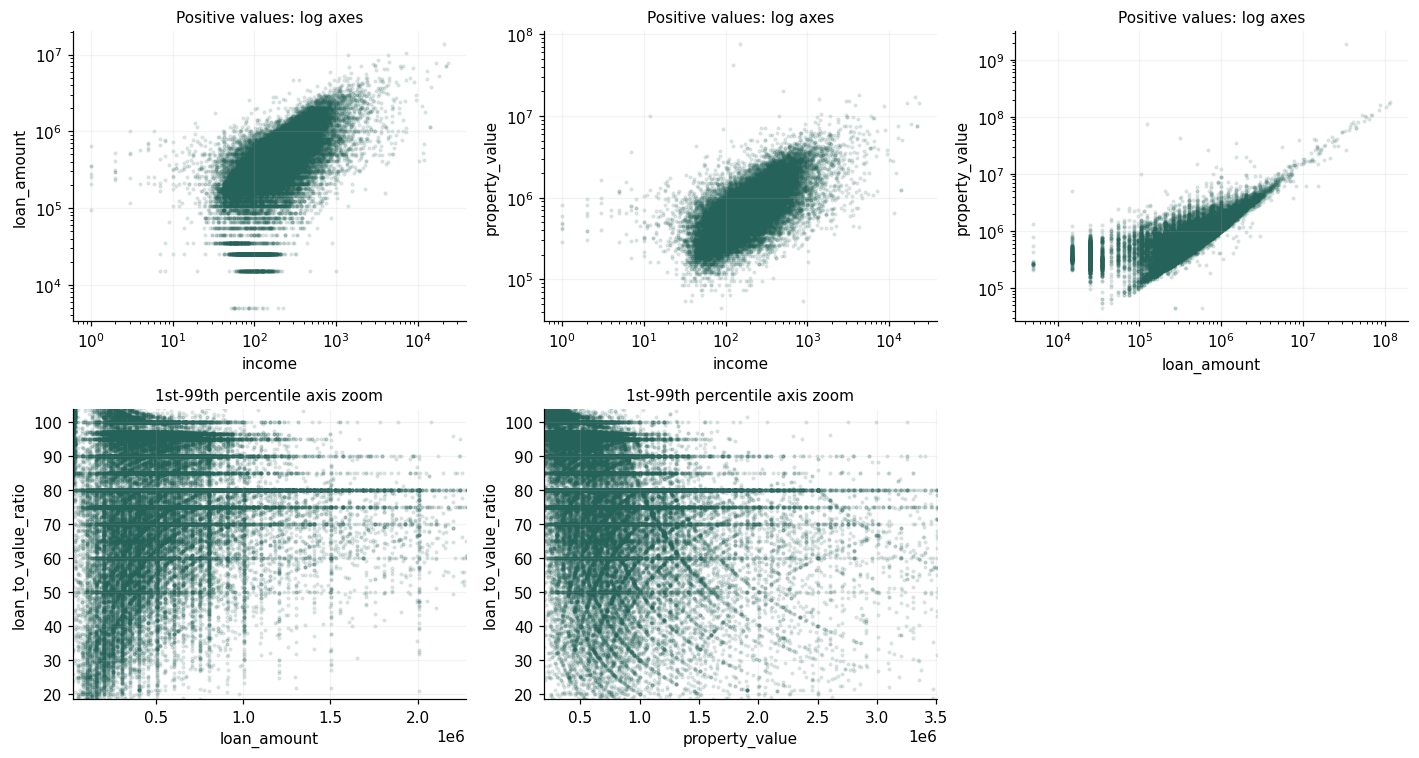

In [ ]:
scatter_pairs = [
    ("income", "loan_amount"),
    ("income", "property_value"),
    ("loan_amount", "property_value"),
    ("loan_amount", "loan_to_value_ratio"),
    ("property_value", "loan_to_value_ratio")
]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, pair in zip(axes.flat, scatter_pairs):
    x_col, y_col = pair
    valid_pair = numeric[x_col].notna() & numeric[y_col].notna()
    if y_col != "loan_to_value_ratio":
        log_ok = valid_pair & numeric[x_col].gt(0) & numeric[y_col].gt(0)
        ax.scatter(numeric.loc[log_ok, x_col], numeric.loc[log_ok, y_col],
                   s=3, alpha=0.12, color="#256259", rasterized=True)
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_title("Positive values: log axes", fontsize=10)
        print(pair, "쌍별 관측:", valid_pair.sum(), "로그 눈금 제외:", (valid_pair & ~log_ok).sum())
    else:
        ax.scatter(numeric.loc[valid_pair, x_col], numeric.loc[valid_pair, y_col],
                   s=3, alpha=0.12, color="#256259", rasterized=True)
        x_low, x_high = numeric.loc[valid_pair, x_col].quantile([0.01, 0.99])
        y_low, y_high = numeric.loc[valid_pair, y_col].quantile([0.01, 0.99])
        ax.set_xlim(x_low, x_high)
        ax.set_ylim(y_low, y_high)
        in_view = numeric[x_col].between(x_low, x_high) & numeric[y_col].between(y_low, y_high)
        print(pair, "쌍별 관측:", valid_pair.sum(), "확대 축 범위 밖:", (valid_pair & ~in_view).sum())
        ax.set_title("1st-99th percentile axis zoom", fontsize=10)
    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)
axes[1, 2].axis("off")
plt.tight_layout()
plt.show()

**해석:** 금액·소득은 폭이 넓어 원래 눈금만으로는 중심부가 압축된다. 로그 눈금으로 양수값을 보면 소득–대출금액·소득–부동산가치·대출금액–부동산가치에 양의 관계가 보이고, 상관표의 순위 관계와 함께 읽을 수 있다. 로그 눈금에서 0·음수는 표시할 수 없어 해당 쌍의 제외 수를 명시했다. 이는 원자료에서 제거한 것이 아니다. CLTV는 금액 하나에 따라 일렬로 결정되지 않으며 다양한 비율이 존재한다. 축 확대에서 안 보이는 극단값은 ④와 ⑧의 전체 범위 점검으로 보완한다.

## ⑧ 이상값 및 데이터 품질 점검
### 8-1. 검토 기준에 걸리는 값의 규모
수치 범위와 특수코드는 별개다. 아래 금액·CLTV·기간 기준은 **확인할 행을 찾기 위한 탐색 기준**이다. 기준을 넘었다고 오류나 삭제 대상으로 확정하지 않는다. 비율의 분모는 숫자 관측 건수가 아니라 전체 신청 70,304건으로 통일한다.

In [ ]:
quality_flags = pd.DataFrame(index=df.index)
quality_flags["소득_음수"] = numeric["income"] < 0
quality_flags["소득_0"] = numeric["income"] == 0
quality_flags["소득_1000천USD초과"] = numeric["income"] > 1000
quality_flags["대출_0이하"] = numeric["loan_amount"] <= 0
quality_flags["대출_1000만USD초과"] = numeric["loan_amount"] > 10000000
quality_flags["부동산_0이하"] = numeric["property_value"] <= 0
quality_flags["부동산_1000만USD초과"] = numeric["property_value"] > 10000000
quality_flags["CLTV_0이하"] = numeric["loan_to_value_ratio"] <= 0
quality_flags["CLTV_100초과"] = numeric["loan_to_value_ratio"] > 100
quality_flags["CLTV_150초과"] = numeric["loan_to_value_ratio"] > 150
quality_flags["기간_0이하"] = numeric["loan_term"] <= 0
quality_flags["기간_12개월미만"] = numeric["loan_term"] < 12
quality_flags["기간_360개월초과"] = numeric["loan_term"] > 360
quality_flags["기간_정수아님"] = numeric["loan_term"].notna() & (numeric["loan_term"] % 1 != 0)
quality_summary = quality_flags.sum().to_frame("건수")
quality_summary["전체대비_pct"] = quality_summary["건수"] / len(df) * 100
display(quality_summary)

# 공식 2025 FIG Q653은 검토 권고이며 오류 확정 규칙이 아니다.
cltv_review = ((decision == "Approved") & (numeric["loan_to_value_ratio"] > 250))
cltv_review = cltv_review | ((decision == "Denied") & (numeric["loan_to_value_ratio"] > 1000))
print("FIG Q653 상한 검토 범위를 넘는 기록:", cltv_review.sum())

,건수,전체대비_pct
소득_음수,32,0.046
소득_0,511,0.727
소득_1000천USD초과,813,1.156
대출_0이하,0,0.000
대출_1000만USD초과,84,0.119
부동산_0이하,0,0.000
부동산_1000만USD초과,100,0.142
CLTV_0이하,0,0.000
CLTV_100초과,2241,3.188
CLTV_150초과,13,0.018


FIG Q653 상한 검토 범위를 넘는 기록: 0


**실제 결과와 판단:**

| 점검 대상 | 관측 건수·값 | 분류와 판단 |
|---|---|---|
| 음수·0 소득 | 음수 32건, 0은 511건 | 실제 소득 보고값일 수 있음. [2025 FIG는 음수 허용](https://ffiec.cfpb.gov/documentation/fig/2025/overview). 원인 확인 전 오류 판정 금지 |
| 고소득 | 1,000천 USD 초과 813건, 최대 23,170천 USD | 실제 고소득/손익 등의 가능성과 오류 가능성을 구분할 근거 부족. 단위 혼동 주의 |
| 고액 대출 | 10,000,000 USD 초과 84건 | 실제 거래 규모와 입력 오류 가능성을 모두 남김 |
| 고액 부동산 | 10,000,000 USD 초과 100건, 최대 1,861,825,000 USD | 특히 큰 최댓값은 개별 기록 검토 필요. 현재 오류 여부는 확인할 수 없음 |
| 높은 CLTV | 100% 초과 2,241건, 150% 초과 13건 | 실제 고레버리지 또는 평가·담보구조 차이 가능. 100%를 오류 경계로 사용하지 않음 |
| 기간 | 12개월 미만 35건, 360개월 초과 547건, 최대 492개월 | 단기/특수상품 또는 오류 가능성. 양의 정수 조건은 모두 충족 |
| 비양수 대출·가치·CLTV·기간 | 모두 0건 | 탐색한 이 규칙에서는 발견되지 않음. 전체 품질 보장은 아님 |

FIG의 CLTV Q653 검토 상한(승인 계열 250, 거절 계열 1,000)을 넘는 값은 **0건**이다. 따라서 342.188%라는 최댓값만으로 공식 입력 오류라고 할 근거는 없다. 공식 검토 범위 안이라는 것이 개별 행의 정확성을 보장하지도 않는다. [2025 FIG Q653](https://ffiec.cfpb.gov/documentation/fig/2025/overview)

**HMDA 특수코드:** `NA`, `Exempt`, 연령 `8888` 및 정보 비가용 범주는 수치 극단값이 아니다. ③에서 별도 집계했으며 해당 값들을 임의의 0이나 실제 8888세로 취급하지 않는다.

### 8-2. 극단적인 행을 함께 읽기
각 변수의 상·하위 기록과 다른 선택 변수들을 같이 본다. 화면의 index는 원본에서의 행 위치를 찾기 위한 표시이며 영구적인 대출 ID가 아니다. 출력 기록은 검사 대상으로만 남긴다.

In [ ]:
inspection_columns = ["action_taken", "income", "loan_amount", "property_value",
                      "loan_to_value_ratio", "loan_term", "debt_to_income_ratio",
                      "loan_type", "lien_status", "occupancy_type", "county_code",
                      "preapproval", "total_units"]
for col in ["income", "loan_amount", "property_value", "loan_to_value_ratio", "loan_term"]:
    print("\n", col, "큰 값 3개")
    display(df.loc[numeric[col].nlargest(3).index, inspection_columns])
    print(col, "작은 값 3개")
    display(df.loc[numeric[col].nsmallest(3).index, inspection_columns])

print("숫자로 관측된 기간의 주요 빈도")
display(numeric["loan_term"].value_counts().head(12).to_frame("건수"))


 income 큰 값 3개


,action_taken,income,loan_amount,property_value,loan_to_value_ratio,loan_term,debt_to_income_ratio,loan_type,lien_status,occupancy_type,county_code,preapproval,total_units
64400,3,"23,170.000","7,835,000.000",14255000,55,360,50%-60%,1,1,3,"25,019.000",2,1
60284,2,"22,029.000","7,005,000.000",7505000,93.333,360,<20%,1,1,1,"25,023.000",2,1
60285,2,"22,029.000","7,005,000.000",7505000,93.333,360,<20%,1,1,1,"25,021.000",2,1


income 작은 값 3개


,action_taken,income,loan_amount,property_value,loan_to_value_ratio,loan_term,debt_to_income_ratio,loan_type,lien_status,occupancy_type,county_code,preapproval,total_units
62837,3,"-7,407.000","745,000.000",935000,80,360,<20%,1,1,1,"25,017.000",2,1
5755,1,"-3,775.000","1,525,000.000",Exempt,Exempt,Exempt,Exempt,1,1,2,"25,001.000",2,1
3027,3,-968.000,"1,205,000.000",5505000,56.251,300,<20%,1,2,1,"25,021.000",2,1



 loan_amount 큰 값 3개


,action_taken,income,loan_amount,property_value,loan_to_value_ratio,loan_term,debt_to_income_ratio,loan_type,lien_status,occupancy_type,county_code,preapproval,total_units
2637,1,NaN,"116,755,000.000",181755000,64.2,84,NaN,1,1,3,"25,021.000",2,>149
2143,1,NaN,"113,195,000.000",166005000,72.100000,60,NaN,1,1,3,"25,023.000",2,>149
624,1,NaN,"102,785,000.000",150005000,72.900000,60,NaN,1,1,3,"25,017.000",2,>149


... (12 outputs left out)

loan_term 작은 값 3개


,action_taken,income,loan_amount,property_value,loan_to_value_ratio,loan_term,debt_to_income_ratio,loan_type,lien_status,occupancy_type,county_code,preapproval,total_units
1402,1,NaN,"1,055,000.000",1405000,75,6,NaN,1,1,3,"25,017.000",2,1
1429,3,207.000,"1,055,000.000",1245000,85,6,>60%,1,1,1,"25,017.000",2,1
3014,2,182.000,"1,205,000.000",1535000,78.431,6,>60%,1,1,3,"25,021.000",2,1


숫자로 관측된 기간의 주요 빈도


,건수
loan_term,
360.000,57132
180.000,2530
300.000,2086
240.000,1080
12.000,951
120.000,690
480.000,316
372.000,208
60.000,159


**해석:** 부동산가치 최댓값 행(index 23738)은 실행(1), 투자용(occupancy 3), 대출금액 33,225,000 USD, CLTV 1.78%, 소득 NA, 84개월이다. 추가한 `total_units`는 `>149`로, 해당 담보 부동산 관련 주거단위가 150개 이상인 공개 구간이다. 따라서 일반 1세대 주택과 다른 규모의 기록임을 확인할 수 있다. 부동산가치 상위 5건 모두 `>149`이다. 다만 정확한 단위수·법인 여부·개별 금액의 정확성·보고 오류 여부까지 확인된 것은 아니다.

초고액 부동산 상위 기록에서 소득 NA와 짧은 기간이 함께 나타나는 것도, 소득 결측을 임의의 평균으로 채우기 전에 거래 범위를 확인해야 할 이유다. 480개월은 316건, 372개월은 208건으로 단일 오타 한두 건만의 현상은 아니다. 그러나 빈도가 있다는 것만으로 정확성이 검증되지는 않는다. 이번에 추가한 주거단위수로 담보 규모를 구분할 수 있다. 상품·기관 등 나머지 맥락은 이후 추가 확인 대상으로 남긴다.

### 8-3. 공개 금액 처리·동일행·코드 범위
금액이 일정 간격으로 나타나는지 확인한다. 또 17개 변수가 같은 기록이 있더라도 동일 신청이 중복 수록되었다고 바로 판단하지 않는다. 공개 데이터의 정밀도 제한과 선택변수 수 때문에 다른 신청이 같은 값으로 보일 수 있다.

In [ ]:
amount_publication = pd.DataFrame(index=["loan_amount", "property_value"])
for col in ["loan_amount", "property_value"]:
    amount_publication.loc[col, "숫자관측"] = numeric[col].notna().sum()
    amount_publication.loc[col, "10000달러구간_중간값"] = numeric[col].mod(10000).eq(5000).sum()
display(amount_publication)
print("17개 값이 같은 후속 기록 수:", df.duplicated().sum())

expected_categories = {
    "action_taken": ["1", "2", "3"],
    "preapproval": ["1", "2"],
    "total_units": ["1", "2", "3", "4", "5-24", "25-49", "50-99", "100-149", ">149"],
    "loan_type": ["1", "2", "3", "4"],
    "lien_status": ["1", "2"],
    "occupancy_type": ["1", "2", "3"],
    "applicant_age": ["<25", "25-34", "35-44", "45-54", "55-64", "65-74", ">74", "8888"],
    "derived_sex": ["Male", "Female", "Joint", "Sex Not Available"],
    "derived_race": ["American Indian or Alaska Native", "Asian", "Black or African American",
                     "Native Hawaiian or Other Pacific Islander", "White",
                     "2 or more minority races", "Joint", "Free Form Text Only", "Race Not Available"],
    "derived_ethnicity": ["Hispanic or Latino", "Not Hispanic or Latino", "Joint",
                          "Ethnicity Not Available", "Free Form Text Only"],
    "debt_to_income_ratio": dti_order,
    "county_code": list(county_names.keys()) + ["NA"]
}
for col in expected_categories:
    unexpected = df_text.loc[~df_text[col].isin(expected_categories[col]), col]
    print(col, "예상 목록 밖 표기:", unexpected.value_counts().to_dict())

# 공식 V613: Action 3이면 preapproval은 2여야 한다.
preapproval_conflict = df["action_taken"].eq(3) & df["preapproval"].ne(2)
print("사전승인 V613 조합 불일치 건수:", preapproval_conflict.sum())

,숫자관측,10000달러구간_중간값
loan_amount,"70,304.000","70,304.000"
property_value,"65,409.000","65,409.000"


17개 값이 같은 후속 기록 수: 248
action_taken 예상 목록 밖 표기: {}
preapproval 예상 목록 밖 표기: {}
total_units 예상 목록 밖 표기: {}
loan_type 예상 목록 밖 표기: {}
lien_status 예상 목록 밖 표기: {}
occupancy_type 예상 목록 밖 표기: {}
applicant_age 예상 목록 밖 표기: {}
derived_sex 예상 목록 밖 표기: {}
derived_race 예상 목록 밖 표기: {}
derived_ethnicity 예상 목록 밖 표기: {}
debt_to_income_ratio 예상 목록 밖 표기: {}
county_code 예상 목록 밖 표기: {}
사전승인 V613 조합 불일치 건수: 0


**해석:** 대출금액 **70,304/70,304건**, 숫자 부동산가치 **65,409/65,409건**이 모두 10,000달러 구간 중간값 형태다. 금액 끝자리가 5,000이라고 조작이나 오류라고 볼 수 없다. [CFPB의 공개 정밀도 조정 정책](https://www.federalregister.gov/documents/2019/01/31/2018-28404/disclosure-of-loan-level-hmda-data)과 일치하는 관측이다. 두 금액은 정밀도가 줄어든 공개값이고 CLTV의 분자는 해당 담보의 총부채이므로, `loan_amount / property_value × 100`이 보고 CLTV와 정확히 같아야 한다는 검증 규칙을 만들지 않는다.

17개 값이 앞선 기록과 모두 같은 후속 행은 **248건**이다. 이는 선택 열 기준 `duplicated()` 결과이며 실제 중복 신청인지 확인한 수가 아니다. 따라서 제거하지 않는다. 코드 범위 점검에서 예상 목록 밖 값은 발견되지 않았다. 표본이 작은 범주와 정보 비가용 표기가 존재한다는 문제는 여전히 남는다.

**추가 변수 품질:** 두 변수 모두 원문 빈칸·NA·Exempt와 예상 범주 밖 값은 없다. `total_units`의 `5-24`~`>149`는 정상적인 공개 구간이며 결측·오류가 아니다. Action 3과 사전승인 요청의 조합 불일치도 0건이다. [공개 필드](https://ffiec.cfpb.gov/documentation/publications/loan-level-datasets/lar-data-fields#total_units), [2025 FIG V613](https://ffiec.cfpb.gov/documentation/fig/2025/overview).

## ⑨ EDA 최종 정리와 다음 단계 판단
### 9-1. 이 데이터의 구조
- 제공 CSV는 **70,304행·99열**, 분석용 `df`는 **70,304행·17열**이다. 2025년 MA·주택구입·Action 1/2/3 조건이 파일과 일치한다.
- 금융기관 기준 승인 **64,289건(91.44%)**, 거절 **6,015건(8.56%)**, 비율은 **10.69:1**이다. Action 2는 1,489건이며 실행과 구분해서 보존했다.
- Conventional 87.35%, 선순위 93.34%, 주거주 85.71%가 중심이다. 동시에 후순위·투자용·초고액 거래도 포함한다. 사전승인 요청은 3,609건(5.13%), 1세대 담보는 61,836건(87.96%), 5세대 이상 공개 구간은 합계 780건(1.11%)이다. “동일한 조건의 일반 개인 주담대” 집단으로 보기는 어렵다.
- 숫자 관측 중앙값: 소득 153천 USD, 대출 475,000 USD, 부동산 635,000 USD, CLTV 80%, 기간 360개월. 소득·금액은 오른쪽 극단값이 크고 기간은 360개월에 집중한다.

### 9-2. 실제 확인된 주요 인사이트

| 관측 결과 | 근거 | 분석적 의미 |
|---|---|---|
| 고DTI에서 높은 거절률 | 50%-60% 956/4,668=20.48%, >60% 1,589/1,956=81.24% | 선형 한 계수보다 구간 차이를 우선 검토할 후보 |
| DTI가 전체에서 단조롭지는 않음 | <20% 10.37% vs 20%-<30% 3.92%; 36~49 내 오르내림 | 낮은 DTI이면 항상 안전하다고 단정 불가 |
| 후순위에서 높은 거절률 | 1,163/4,681=24.85% vs 선순위 4,852/65,623=7.39% | 상품·DTI와 함께 볼 중요한 구분 |
| 승인군의 소득·대출금액이 더 큼 | 소득 중앙값 157 vs 116천 USD, 대출 485,000 vs 405,000 USD | 큰 대출 자체가 불리하다는 단순 예상과 다름 |
| CLTV 중심의 차이는 작음 | 두 그룹 중앙값 80%, 평균 77.70 vs 78.96% | 단순 중심 비교만으로 거절을 구분하기는 어려움 |
| 인구학적 집단별 관측 격차 | Black 16.34% vs White 7.14%, Hispanic 14.15% vs Not Hispanic 7.56%, Joint 성별집계 6.19% | 원인 규명을 위한 후속 질문이며 인과·차별 판단 아님 |
| 지역별 차이가 있음 | Hampshire 64/1,238=5.17%, Suffolk 673/6,248=10.77% | 지역 구성 차이를 함께 고려해야 함 |
| 정보 부재 자체가 결과와 관련 | 부동산가치 NA 351/563=62.34%, 기간 NA 54/78=69.23% | 삭제·대치 전 발생 원인과 정보 시점 확인 필요 |
| 금액의 순위 중복이 큼 | 대출–부동산 Spearman 0.798 vs Pearson 0.365 | 극단값·치우침을 고려한 중복 검토 필요 |
| 사전승인 요청 집단에 거절이 없음 | 요청 0/3,609=0%, 미요청 6,015/66,695=9.02% | V613 보고 규칙과 Action 필터의 구조적 관계. 사전승인의 보호 효과로 해석 금지 |
| 주거단위수별 거절률 차이 | 1세대 4,854/61,836=7.85%, 2세대 631/4,944=12.76%, 3세대 381/2,192=17.38%, 4세대 88/552=15.94% | 1세대와 2~4세대의 구성 차이 확인; 5세대 이상 구간은 소표본 주의 |
| 초고액 담보의 규모 확인 | 부동산가치 상위 5건 모두 total_units >149 | 150세대 이상 담보가 섞여 있음. 정확한 가격 타당성까지 검증된 것은 아님 |

**해석의 범위:** 위 표는 기술적 관측 결과다. 신용점수, 기관, 주거단위수 이외의 주택구조 등 미선택 요인이 있으며 원인이나 독립 효과를 분리하지 않았다. “DTI가 높아서 이 신청이 거절되었다” 또는 “이 집단에 대한 차별이 있다”는 개별·인과 결론은 낼 수 없다.

### 9-3. 품질 문제와 다음 단계의 구체적인 판단

| 대상 | EDA 근거 | 이후 검토할 처리·분석 | 이번 상태 |
|---|---|---|---|
| DTI | NA/Exempt 8,202건(11.67%), 공개 구간 혼재 | NA와 Exempt 발생 맥락 분리; 36~49 원문 유지 또는 근거 있는 구간 재구성 비교 | 원문 보존 |
| 소득 | NA 4,426건, 음수 32건·0은 511건 | 소득 NA가 적용 불가인지 확인; 거래 범위에 맞는 결측 처리; 양수의 로그 검토와 0·음수 별도 방침 | 삭제·대치·로그 없음 |
| CLTV·부동산가치 | 비숫자 5,512·4,895건, NA집단 높은 거절률 | 면제와 적용 불가 분리; 관측 여부의 예측 시점 확인; 극단 기록 검토 | 임시 숫자 요약만 |
| 대출기간 | 비숫자 4,411건, 360개월 집중, IQR=0 | 단순 연속형과 기간 구분 중 어떤 해석이 나은지 검토; 짧은 기간·372·480개월 맥락 확인 | 원래 기간 보존 |
| 인종·ethnicity·성별 | 정보 비가용 및 Joint·Free Text 존재 | derived 정의를 반영한 집단 비교; 소표본 범주 병합의 의미와 정보 손실 검토; 설명용/예측용 목적 구분 | 범주 병합 없음 |
| 연령 | 8888은 2,969건 | 8888을 실제 연령에서 분리; 연령대 순서 유지; 수치 중간값 강제 대입 지양 | 코드 보존 |
| County | NA 266건 거절률 36.84%, Dukes/Nantucket 소표본 | NA를 County로 취급하지 않기; 지역 비교 시 분모와 구성 함께 확인 | 표시용 이름만 매칭 |
| 소득·대출·부동산가치 | 큰 극단값과 양의 순위 상관 | 대출·부동산은 양수 로그를 검토; 변환 후 공선성과 설명력 확인 | 변환·선택 없음 |
| 대출/신청 범위 | 투자용·후순위·초고액 및 5세대 이상 780건 포함 | 확인한 주거단위수와 거래/기관·상품 정보를 바탕으로 분석 범위 결정 | 필터 추가 없음 |
| preapproval | 요청 집단 거절 0건; V613과 표본 필터로 설명되는 구조 | EDA에는 유지하되 Action 3 예측에 바로 채택하지 않기; 보고 규칙에 따른 타깃 유출·분리 문제 검토 | 코드 보존·모델링 없음 |
| total_units | 개수와 구간 혼재, 1세대 87.96%, 25세대 이상 구간은 각각 58·44·9·21건 | 범주형 유지; 목적에 따라 1/2~4/5+ 등 재구성 검토, 초고액 맥락 확인 | 구간 보존·병합 없음 |
| 보고 정보의 시점 | NA·Exempt와 거절률 차이 | 신청 시점 예측인지 심사 후 결과 설명인지 확정; 전자라면 결과 후 생성 정보 유입 여부 확인 | 예측변수 확정 없음 |
| 중복처럼 보이는 행 | 17개 값 동일한 후속 행 248건 | 고유 식별 정보 없이 실제 중복으로 간주하지 않음 | 중복 삭제 없음 |
| 클래스 불균형 | 거절 8.56% | 후속 모델 검증에서 거절 탐지 성능과 승인 편향 확인, 평가 설계 별도 수립 | 모델 학습 없음 |

**우선 결정할 순서:** ① 분석 대상이 이 파일 전체인지 개인·일반 주택 대출로 좁힐지 → ② 결과 설명인지 신청 시점 예측인지 → ③ NA/Exempt/정보 비가용별 원인과 처리 → ④ 기간·DTI 등의 범주 구성 → ⑤ 변환·중복 변수와 모형 비교. 지금 EDA만으로 특정 대치법이나 삭제 기준을 확정하지 않는다.

### 9-4. 원본·분석용 자료 보존 확인
아래 확인은 원본의 값과 열, 분석용 df의 선택된 값과 전체 행이 그대로 남았는지 검증한다. 숫자 변환·상태 라벨·이름 매핑이 원자료에 반영되지 않았음을 마지막에 확인한다.

In [ ]:
raw_hash_after = pd.util.hash_pandas_object(df_raw, index=True)
assert raw_hash_before.equals(raw_hash_after)
assert df_raw.columns.tolist() == raw_columns_before
assert df.columns.tolist() == selected_columns
assert len(df) == len(df_raw)
assert df.equals(df_raw[selected_columns])
print("검증 통과: df_raw 보존, df 17개 원본 열 보존, 전체 행 유지")
print("최종 df 크기:", df.shape)
print("이 단계에서 결측 삭제·대치·이상값 제거·변수 삭제·모형 학습은 수행하지 않았습니다.")

검증 통과: df_raw 보존, df 17개 원본 열 보존, 전체 행 유지
최종 df 크기: (70304, 17)
이 단계에서 결측 삭제·대치·이상값 제거·변수 삭제·모형 학습은 수행하지 않았습니다.


## 출처와 재현 메모

1. **수치 결과의 직접 출처:** 제공받은 `actions_taken_1-2-3_loan_purposes_1_state_MA.csv`. 모든 비율은 본문 코드의 건수/분모로 산출했다. 이 노트북의 정적 해석은 70,304건인 제공 파일에 해당한다. CSV가 바뀌면 코드를 재실행하고 해석도 다시 확인해야 한다.
2. [CFPB/FFIEC Public HMDA LAR Data Fields](https://ffiec.cfpb.gov/documentation/publications/loan-level-datasets/lar-data-fields): Action·상품·담보순위·이용목적·derived 범주·preapproval·total_units·단위와 정의.
3. [2025 Filing Instructions Guide](https://ffiec.cfpb.gov/documentation/fig/2025/overview): 연령 8888, 소득의 단위·음수 허용, NA/Exempt 보고 의미, CLTV·기간 규칙, Q653 검토 범위와 preapproval–Action 조합 규칙 V613.
4. [CFPB, Disclosure of Loan-Level HMDA Data, 2019-01-31](https://www.federalregister.gov/documents/2019/01/31/2018-28404/disclosure-of-loan-level-hmda-data): 공개 금액의 10,000달러 구간 중간값 및 연령·DTI 등의 공개 정밀도 조정. 공개 방식의 배경 자료이며 2025 파일의 실제 표기는 본문에서 별도 확인했다.
5. [U.S. Census Bureau, Massachusetts Counties — 2025](https://tigerweb.geo.census.gov/tigerwebmain/Files/acs25/tigerweb_acs25_county_ma.html): County FIPS 이름 매칭. 원본 코드와 별개 비교표에서만 사용했다.

외부 자료 확인일은 2026-11-04이다. 분석 코드는 pandas·numpy·matplotlib와 Jupyter의 표 표시 기능만 사용한다. 결과 표시는 실행된 상태로 포함했다.